# Challenge 2 — Log Analysis

## Objective

Identify which endpoints are compromised, determine how the compromise occurred,
correlate evidence across web activity, endpoint security and USB logs,
reconstruct the relevant timeline, and suggest appropriate remedial measures.

## Dataset

The investigation uses endpoint-agent logs covering September 2026:

- `web_activity.csv` — Web destinations contacted by endpoints
- `endpoint_security.csv` — Antivirus, quarantine and web-filter events
- `usb_events.csv` — USB device activity

## Safety

This analysis is performed passively. Log entries containing internet domains
or IP addresses will be treated as data only. Suspicious destinations will not
be opened in a browser or contacted from the analysis machine.

## Analysis Environment

- Operating System: macOS
- IDE: Visual Studio Code
- Language: Python
- Primary libraries: Pandas, Matplotlib, NetworkX

In [2]:
%pip install networkx


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path
import hashlib
import os

print("Libraries imported successfully.")


Libraries imported successfully.


In [4]:
data_folder = Path("web_activity/data")

web_file = data_folder / "web_activity.csv"
security_file = data_folder / "endpoint_security.csv"
usb_file = data_folder / "usb_events.csv"

print("All libraries imported successfully.")
print()

print("Checking dataset files:")
print("Web activity file:", web_file.exists())
print("Security log file:", security_file.exists())
print("USB log file:", usb_file.exists())

All libraries imported successfully.

Checking dataset files:
Web activity file: True
Security log file: True
USB log file: True


In [5]:
web_data = pd.read_csv(web_file, nrows=5)

print("Columns in web activity log:")
print(web_data.columns.tolist())

print("\nFirst 5 records:")
display(web_data)

Columns in web activity log:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message']

First 5 records:


,endpoint_id,endpoint_name,mac,unit,log_type,event_time,received_time,message
0,EPIEJIZC,host-bbae,E6:AF:E8:AA:EA:49,unit-echo,web,10-09-2026 00:01:34,11-09-2026 09:46:01,192.178.158.84
1,EPIEJIZC,host-bbae,E6:AF:E8:AA:EA:49,unit-echo,web,10-09-2026 00:01:34,11-09-2026 09:46:01,8.8.8.8
2,EPIEJIZC,host-bbae,E6:AF:E8:AA:EA:49,unit-echo,web,10-09-2026 00:01:34,11-09-2026 09:46:01,mail.google.com
3,EPIEJIZC,host-bbae,E6:AF:E8:AA:EA:49,unit-echo,web,10-09-2026 00:01:34,11-09-2026 09:46:01,142.250.29.139
4,EPIEJIZC,host-bbae,E6:AF:E8:AA:EA:49,unit-echo,web,10-09-2026 00:01:34,11-09-2026 09:46:01,dns.google


In [6]:
security_data = pd.read_csv(security_file, nrows=5)
usb_data = pd.read_csv(usb_file, nrows=5)

print("Endpoint security columns:")
print(security_data.columns.tolist())

print("\nUSB event columns:")
print(usb_data.columns.tolist())

print("\nEndpoint security preview:")
display(security_data)

print("\nUSB events preview:")
display(usb_data)

Endpoint security columns:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message']

USB event columns:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message']

Endpoint security preview:


,endpoint_id,endpoint_name,mac,unit,log_type,event_time,received_time,message
0,EPZRAPEL,host-d14b,8A:58:3E:18:FD:1B,unit-foxtrot,quarantine,01-09-2026 04:58:58,01-09-2026 04:58:56,No suspicious file found by type or extension.
1,EPZRAPEL,host-d14b,8A:58:3E:18:FD:1B,unit-foxtrot,quarantine,01-09-2026 04:58:58,01-09-2026 04:58:56,File: 53EDA42869D426262B752F088EA605187284ACE8...
2,EPYJFFRM,host-2864,F2:EA:9C:78:DC:3C,unit-oscar,quarantine,01-09-2026 05:20:37,01-09-2026 05:20:39,No suspicious file found by type or extension.
3,EPYJFFRM,host-2864,F2:EA:9C:78:DC:3C,unit-oscar,quarantine,01-09-2026 05:20:37,01-09-2026 05:20:39,No Malicious files found.
4,EPFFTO5T,host-508b,FA:2F:46:B7:14:23,unit-delta,quarantine,01-09-2026 08:50:38,01-09-2026 08:50:38,No suspicious file found by type or extension.



USB events preview:


,endpoint_id,endpoint_name,mac,unit,log_type,event_time,received_time,message
0,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:12,22-09-2026 19:03:03,"General -UDisk , Mass Storage abcd:1234"
1,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:41,22-09-2026 19:03:03,"General -UDisk , Mass Storage abcd:1234"
2,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:12,23-09-2026 09:05:16,"General -UDisk , Mass Storage abcd:1234"
3,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:41,23-09-2026 09:05:16,"General -UDisk , Mass Storage abcd:1234"
4,EP7FZ2XY,host-9764,F6:6F:85:06:00:26,unit-quebec,usb,07-09-2026 22:34:11,07-09-2026 09:03:19,"usb-usage: Logitech-USB Optical Mouse, Human I..."


In [7]:
hash_file = data_folder / "SHA256SUMS"

print("SHA256 file exists:", hash_file.exists())

print("\nSHA256 records:")
print(hash_file.read_text())

SHA256 file exists: True

SHA256 records:
9e727f2e841566743f11dbc7ba844e886b62dba7057fafa16a5beb8e6d294073  README.md
db90087e2eacc0b0fe7b670993cd4267bd5d9b8e258704e4ab165aa793f05ed3  data/web_activity.csv
4eec010c1852cc0b1382debf335e69a819fac168005f8a3393f880fbc86252a1  data/endpoint_security.csv
8c92bfad3a2fb7f8c2c8148d4e91e44946b1536f3b693e3309e71eac8942d194  data/usb_events.csv
61fb6f8e77df47759016e07c9e845a9ae81aecbd72bc4a1f868da75890e80684  endpoint-logs-challenge.7z



In [8]:
def get_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        while True:
            data = file.read(1024 * 1024)

            if not data:
                break

            sha256.update(data)

    return sha256.hexdigest()


print("Web activity:", get_sha256(web_file))
print("Security log:", get_sha256(security_file))
print("USB log:", get_sha256(usb_file))

Web activity: db90087e2eacc0b0fe7b670993cd4267bd5d9b8e258704e4ab165aa793f05ed3
Security log: 4eec010c1852cc0b1382debf335e69a819fac168005f8a3393f880fbc86252a1
USB log: 8c92bfad3a2fb7f8c2c8148d4e91e44946b1536f3b693e3309e71eac8942d194


In [9]:
web_data = pd.read_csv(web_file)

print("Total records:", len(web_data))
print("Unique endpoints:", web_data["endpoint_id"].nunique())
print("Unique units:", web_data["unit"].nunique())

print("\nLog types:")
print(web_data["log_type"].value_counts())

print("\nDate range:")
print(web_data["event_time"].min(), "to", web_data["event_time"].max())

Total records: 2812118
Unique endpoints: 248
Unique units: 19

Log types:
log_type
web    2812118
Name: count, dtype: int64

Date range:
10-09-2026 00:01:34 to 21-09-2026 23:09:01


In [10]:
web_data["event_time"] = pd.to_datetime(
    web_data["event_time"],
    dayfirst=True
)

web_data["received_time"] = pd.to_datetime(
    web_data["received_time"],
    dayfirst=True
)

print("Event time range:")
print(web_data["event_time"].min())
print("to")
print(web_data["event_time"].max())

print("\nReceived time range:")
print(web_data["received_time"].min())
print("to")
print(web_data["received_time"].max())

Event time range:
2026-09-10 00:01:34
to
2026-09-21 23:09:01

Received time range:
2026-09-10 06:43:20
to
2026-09-22 11:29:54


In [11]:
endpoint_activity = (
    web_data
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="web_requests")
    .sort_values("web_requests", ascending=False)
)

print("Top 20 endpoints by web activity:")
display(endpoint_activity.head(20))

Top 20 endpoints by web activity:


,endpoint_id,endpoint_name,unit,web_requests
147,EPMQTKSL,host-942d,unit-charlie,57844
82,EPEWYRFX,host-2562,unit-charlie,52908
201,EPTDOI6T,host-4a53,unit-india,42674
108,EPHXH7MS,host-97f9,unit-quebec,40662
93,EPG67237,host-de5a,unit-bravo,37913
25,EP65VPYQ,host-0b94,unit-bravo,36153
157,EPNWM26Q,host-f23e,unit-oscar,34676
47,EPAR5TSH,host-e6cb,unit-charlie,34185
158,EPNXD2NI,host-bfb4,unit-quebec,32797
21,EP5KBVLG,host-ee2b,unit-romeo,32409


In [12]:
unique_destinations = (
    web_data
    .groupby(["endpoint_id", "endpoint_name", "unit"])["message"]
    .nunique()
    .reset_index(name="unique_destinations")
    .sort_values("unique_destinations", ascending=False)
)

print("Top 20 endpoints by unique destinations:")
display(unique_destinations.head(20))

Top 20 endpoints by unique destinations:


,endpoint_id,endpoint_name,unit,unique_destinations
147,EPMQTKSL,host-942d,unit-charlie,3297
108,EPHXH7MS,host-97f9,unit-quebec,3209
25,EP65VPYQ,host-0b94,unit-bravo,2268
93,EPG67237,host-de5a,unit-bravo,2134
21,EP5KBVLG,host-ee2b,unit-romeo,1989
204,EPTX4FCZ,host-b44e,unit-foxtrot,1870
217,EPVEKWWM,host-aa1b,unit-papa,1665
192,EPSES7ZK,host-4c8d,unit-papa,1659
179,EPQKOBYG,host-d29a,unit-romeo,1596
96,EPGHTVEF,host-8617,unit-quebec,1486


In [13]:
top_destinations = (
    web_data["message"]
    .value_counts()
    .reset_index()
)

top_destinations.columns = ["destination", "requests"]

print("Top 30 most contacted destinations:")
display(top_destinations.head(30))


Top 30 most contacted destinations:


,destination,requests
0,n22ce.svc-72dec3.example,66868
1,198.19.153.92,47316
2,ssl.gstatic.com,44573
3,dns.google,42387
4,play.google.com,41944
5,incoming.telemetry.mozilla.org,37910
6,mail.google.com,37377
7,ns4.fastly.net,35802
8,detectportal.firefox.com,35623
9,34.54.185.247,33704


In [14]:
import re

def is_ip_address(value):
    pattern = r"^\d{1,3}(\.\d{1,3}){3}$"
    return bool(re.match(pattern, str(value).strip()))


web_data["destination_type"] = web_data["message"].apply(
    lambda x: "IP" if is_ip_address(x) else "Domain/Hostname"
)

print("Destination types:")
print(web_data["destination_type"].value_counts())

Destination types:
destination_type
Domain/Hostname    1683609
IP                 1128509
Name: count, dtype: int64


In [15]:
ip_activity = (
    web_data.groupby(["endpoint_id", "endpoint_name", "unit"])
    .agg(
        total_requests=("message", "size"),
        ip_requests=("destination_type", lambda x: (x == "IP").sum())
    )
    .reset_index()
)

ip_activity["ip_percentage"] = (
    ip_activity["ip_requests"] / ip_activity["total_requests"] * 100
)

ip_activity = ip_activity.sort_values(
    "ip_percentage",
    ascending=False
)

print("Top 20 endpoints by direct IP activity:")
display(ip_activity.head(20))

Top 20 endpoints by direct IP activity:


,endpoint_id,endpoint_name,unit,total_requests,ip_requests,ip_percentage
27,EP6D7K7J,host-51f4,unit-india,13365,7974,59.663300
245,EPZOABKY,host-fb53,unit-romeo,27736,16129,58.151860
219,EPVSWBNA,host-e103,unit-delta,10145,5575,54.953179
45,EPAM6DF7,host-b3da,unit-delta,1291,705,54.608830
13,EP4MZIBL,host-ae66,unit-romeo,2380,1286,54.033613
216,EPVC2P55,host-aca0,unit-alpha,6209,3342,53.825093
0,EP2C4ZH5,host-a81b,unit-romeo,17211,9238,53.674975
122,EPJCQSGS,host-df7d,unit-bravo,15997,8574,53.597550
69,EPD3I3JF,host-5715,unit-romeo,1318,706,53.566009
187,EPRD7FJT,host-916a,unit-romeo,12656,6748,53.318584


In [16]:
destination_counts = web_data["message"].value_counts()

print("Total unique destinations:", len(destination_counts))

print("\nDestinations seen only once:")
print((destination_counts == 1).sum())

print("\nDestinations seen 2 times:")
print((destination_counts == 2).sum())

print("\nDestinations seen 3 times:")
print((destination_counts == 3).sum())

Total unique destinations: 19027

Destinations seen only once:
6581

Destinations seen 2 times:
2514

Destinations seen 3 times:
1481


In [17]:
rare_destinations = destination_counts[destination_counts == 1].index

rare_activity = web_data[
    web_data["message"].isin(rare_destinations)
][
    ["endpoint_id", "endpoint_name", "unit", "event_time", "message"]
]

print("Rare destination records:", len(rare_activity))

print("\nSample rare destinations:")
display(rare_activity.head(30))

Rare destination records: 6581

Sample rare destinations:


,endpoint_id,endpoint_name,unit,event_time,message
5087,EPFF7UHG,host-24da,unit-lima,2026-09-10 05:40:30,104.123.150.114
5510,EPFF7UHG,host-24da,unit-lima,2026-09-10 05:52:08,49.44.141.179
5576,EPFF7UHG,host-24da,unit-lima,2026-09-10 05:54:05,49.44.141.144
6145,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:10:55,rr2---sn-q4fl6nsy.googlevideo.com
6153,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:10:55,rr2---sn-q4fl6nsy.googlevideo.com.hgu_lan
6482,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:14:21,ns56.domaincontrol.com
6493,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:14:21,www.asenseinterior.com
6537,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:15:06,163.70.145.63
6550,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:15:06,147.79.69.112
6552,EP63QFAS,host-c4c2,unit-india,2026-09-10 06:15:06,www.skfcontractor.in


In [18]:
rare_by_endpoint = (
    rare_activity
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="rare_destinations")
    .sort_values("rare_destinations", ascending=False)
)

print("Top 20 endpoints with rare destinations:")
display(rare_by_endpoint.head(20))

Top 20 endpoints with rare destinations:


,endpoint_id,endpoint_name,unit,rare_destinations
140,EPMQTKSL,host-942d,unit-charlie,565
102,EPHXH7MS,host-97f9,unit-quebec,499
20,EP5KBVLG,host-ee2b,unit-romeo,242
190,EPTX4FCZ,host-b44e,unit-foxtrot,224
24,EP65VPYQ,host-0b94,unit-bravo,204
36,EP7PCCYI,host-2a10,unit-sierra,136
170,EPQKOBYG,host-d29a,unit-romeo,131
88,EPG67237,host-de5a,unit-bravo,131
202,EPVC2P55,host-aca0,unit-alpha,128
179,EPSES7ZK,host-4c8d,unit-papa,124


In [19]:
security_data = pd.read_csv(security_file)

security_data["event_time"] = pd.to_datetime(
    security_data["event_time"],
    dayfirst=True
)

security_data["received_time"] = pd.to_datetime(
    security_data["received_time"],
    dayfirst=True
)

print("Total security records:", len(security_data))
print("Unique endpoints:", security_data["endpoint_id"].nunique())

print("\nSecurity event types:")
print(security_data["log_type"].value_counts())

print("\nEvent time range:")
print(security_data["event_time"].min())
print("to")
print(security_data["event_time"].max())

Total security records: 23540
Unique endpoints: 247

Security event types:
log_type
quarantine    20004
av_scan        2622
web_block       914
Name: count, dtype: int64

Event time range:
2026-09-01 01:15:01
to
2026-09-26 22:10:02


In [20]:
security_by_endpoint = (
    security_data
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="security_events")
    .sort_values("security_events", ascending=False)
)

print("Top 20 endpoints by security events:")
display(security_by_endpoint.head(20))

Top 20 endpoints by security events:


,endpoint_id,endpoint_name,unit,security_events
166,EPPWQND4,host-79c0,unit-kilo,495
40,EP7XJK3C,host-26a1,unit-alpha,478
16,EP4WW2QO,host-f9f8,unit-india,368
224,EPWHYCYU,host-0843,unit-golf,314
119,EPJ7BIHC,host-1063,unit-india,241
33,EP6WDXYR,host-e670,unit-echo,238
17,EP4YIFHV,host-a616,unit-lima,208
54,EPBIT7ZS,host-0cb9,unit-lima,205
81,EPEWYRFX,host-2562,unit-charlie,203
115,EPIXXNDT,host-e032,unit-kilo,195


In [21]:
quarantine_data = security_data[
    security_data["log_type"] == "quarantine"
]

quarantine_messages = (
    quarantine_data["message"]
    .value_counts()
)

print("Top 20 quarantine messages:")
display(quarantine_messages.head(20))

Top 20 quarantine messages:


message
No suspicious file found by type or extension.                                                                                                                                                                9951
No Malicious files found.                                                                                                                                                                                     9896
File: rawtobr3 | Quarantined At: 2026-09-07 10:58 | FileType: Malicious | SHA256: 64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d92358b64771980665af                                                               5
File: brprintconflsr3 | Quarantined At: 2026-09-07 10:57 | FileType: Malicious | SHA256: 6594cac08d03782ad43d6b293faff904f20032c8eb37a1b27b6caf57b1aeae5e                                                        5
File: chromium.desktop | Quarantined At: 2026-09-02 12:13 | FileType: Unicode text, UTF-8 text | SHA256: 7234de28b960d15c5557206061f209e85bb114ad4d0

In [22]:
malicious_quarantine = quarantine_data[
    quarantine_data["message"].str.contains(
        "FileType: Malicious",
        case=False,
        na=False
    )
]

print("Malicious quarantine events:", len(malicious_quarantine))

print("\nMalicious events by endpoint:")
display(
    malicious_quarantine[
        ["endpoint_id", "endpoint_name", "unit", "event_time", "message"]
    ].sort_values("event_time").head(30)
)

Malicious quarantine events: 134

Malicious events by endpoint:


,endpoint_id,endpoint_name,unit,event_time,message
1,EPZRAPEL,host-d14b,unit-foxtrot,2026-09-01 04:58:58,File: 53EDA42869D426262B752F088EA605187284ACE8...
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,File: recently-used.xbel | Quarantined At: 202...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,File: recently-used.xbel | Quarantined At: 202...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,File: recently-used.xbel | Quarantined At: 202...
1045,EPMQTKSL,host-942d,unit-charlie,2026-09-02 08:37:11,File: recently-used.xbel | Quarantined At: 202...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,File: recently-used.xbel | Quarantined At: 202...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,File: recently-used.xbel | Quarantined At: 202...
3415,EPAGTKNF,host-227c,unit-quebec,2026-09-03 19:03:33,"File: Buy CP PLUS Dashboard Camera, Warranty N..."
3471,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,File: recently-used.xbel | Quarantined At: 202...
2843,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,File: recently-used.xbel | Quarantined At: 202...


In [23]:
malicious_by_endpoint = (
    malicious_quarantine
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="malicious_events")
    .sort_values("malicious_events", ascending=False)
)

print("Endpoints with malicious quarantine events:")
display(malicious_by_endpoint)

Endpoints with malicious quarantine events:


,endpoint_id,endpoint_name,unit,malicious_events
2,EP4YIFHV,host-a616,unit-lima,40
6,EPC2L3UH,host-b4da,unit-india,18
21,EPPGWIOF,host-a656,unit-india,10
14,EPJYEC7F,host-38aa,unit-romeo,10
20,EPOC6Y4R,host-e783,unit-charlie,9
26,EPSES7ZK,host-4c8d,unit-papa,5
5,EPAJI3E5,host-f6a4,unit-oscar,4
18,EPMVZYZO,host-ba01,unit-quebec,4
13,EPJ76RZV,host-aedd,unit-alpha,4
30,EPVSWBNA,host-e103,unit-delta,3


In [24]:
web_summary = (
    web_data
    .groupby("endpoint_id")
    .agg(
        web_requests=("message", "size"),
        unique_destinations=("message", "nunique"),
        ip_requests=("destination_type", lambda x: (x == "IP").sum())
    )
    .reset_index()
)

web_summary["ip_percentage"] = (
    web_summary["ip_requests"] / web_summary["web_requests"] * 100
)

combined = malicious_by_endpoint.merge(
    web_summary,
    on="endpoint_id",
    how="left"
)

combined = combined.merge(
    rare_by_endpoint[
        ["endpoint_id", "rare_destinations"]
    ],
    on="endpoint_id",
    how="left"
)

combined["rare_destinations"] = combined["rare_destinations"].fillna(0)

combined = combined.sort_values(
    "malicious_events",
    ascending=False
)

print("Malicious endpoints with web activity:")
display(combined)

Malicious endpoints with web activity:


,endpoint_id,endpoint_name,unit,malicious_events,web_requests,unique_destinations,ip_requests,ip_percentage,rare_destinations
0,EP4YIFHV,host-a616,unit-lima,40,1034,71,453,43.810445,3.0
1,EPC2L3UH,host-b4da,unit-india,18,280,35,135,48.214286,0.0
2,EPPGWIOF,host-a656,unit-india,10,17213,799,6171,35.850810,21.0
3,EPJYEC7F,host-38aa,unit-romeo,10,3700,220,1733,46.837838,3.0
4,EPOC6Y4R,host-e783,unit-charlie,9,14460,786,7330,50.691563,39.0
5,EPSES7ZK,host-4c8d,unit-papa,5,28268,1659,13866,49.051932,124.0
6,EPAJI3E5,host-f6a4,unit-oscar,4,27333,653,4350,15.914828,13.0
7,EPMVZYZO,host-ba01,unit-quebec,4,7557,317,2955,39.102819,3.0
8,EPJ76RZV,host-aedd,unit-alpha,4,4188,375,2105,50.262655,15.0
9,EPVSWBNA,host-e103,unit-delta,3,10145,387,5575,54.953179,6.0


In [25]:
web_blocks = security_data[
    security_data["log_type"] == "web_block"
]

print("Total web-block events:", len(web_blocks))

print("\nWeb blocks by endpoint:")
display(
    web_blocks
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="web_blocks")
    .sort_values("web_blocks", ascending=False)
    .head(20)
)

Total web-block events: 914

Web blocks by endpoint:


,endpoint_id,endpoint_name,unit,web_blocks
11,EP6WDXYR,host-e670,unit-echo,107
37,EPJ7BIHC,host-1063,unit-india,90
35,EPIXXNDT,host-e032,unit-kilo,90
27,EPGSQVEB,host-9a4f,unit-bravo,53
44,EPMQTKSL,host-942d,unit-charlie,49
50,EPNXD2NI,host-bfb4,unit-quebec,43
20,EPCLJGKA,host-aa31,unit-echo,42
64,EPTX4FCZ,host-b44e,unit-foxtrot,38
68,EPVEKWWM,host-aa1b,unit-papa,34
48,EPNPX6VY,host-6ef6,unit-juliett,34


In [26]:
print("Top web-block messages:")

display(
    web_blocks["message"]
    .value_counts()
    .head(30)
)

Top web-block messages:


message
www.googleapis.com              347
www.facebook.com                179
api.ipify.org                   142
www.linkedin.com                 65
www.instagram.com                52
sync.aralego.com                 48
ecp.yusercontent.com             29
www.dropbox.com                  11
groww.in                          4
farm.plista.com                   4
twitter.com                       4
reddit.com                        4
ssc.33across.com                  3
yandex.ru                         3
www.moneycontrol.com              3
archive.org                       3
assets-money.dailyhunt.in         3
-                                 2
economictimes.indiatimes.com      2
www.livemint.com                  2
www.reddit.com                    1
ip-api.com                        1
github.com                        1
web.whatsapp.com                  1
Name: count, dtype: int64

In [27]:
candidate_blocks = web_blocks[
    web_blocks["endpoint_id"] == "EPMQTKSL"
].sort_values("event_time")

print("Web blocks for EPMQTKSL:", len(candidate_blocks))

display(
    candidate_blocks[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "message"
        ]
    ]
)

Web blocks for EPMQTKSL: 49


,endpoint_id,endpoint_name,unit,event_time,message
2339,EPMQTKSL,host-942d,unit-charlie,2026-09-02 10:43:10,ecp.yusercontent.com
2340,EPMQTKSL,host-942d,unit-charlie,2026-09-02 10:44:10,ecp.yusercontent.com
2341,EPMQTKSL,host-942d,unit-charlie,2026-09-02 10:45:10,ecp.yusercontent.com
4451,EPMQTKSL,host-942d,unit-charlie,2026-09-03 10:49:10,ecp.yusercontent.com
4454,EPMQTKSL,host-942d,unit-charlie,2026-09-03 10:51:10,ecp.yusercontent.com
4449,EPMQTKSL,host-942d,unit-charlie,2026-09-03 10:52:10,ecp.yusercontent.com
4450,EPMQTKSL,host-942d,unit-charlie,2026-09-03 12:07:12,ecp.yusercontent.com
4531,EPMQTKSL,host-942d,unit-charlie,2026-09-05 09:42:09,ecp.yusercontent.com
4184,EPMQTKSL,host-942d,unit-charlie,2026-09-05 09:49:09,sync.aralego.com
5330,EPMQTKSL,host-942d,unit-charlie,2026-09-06 09:46:09,ecp.yusercontent.com


In [28]:
malicious_counts = (
    malicious_quarantine
    .groupby("endpoint_id")
    .size()
    .reset_index(name="malicious_events")
)

block_counts = (
    web_blocks
    .groupby("endpoint_id")
    .size()
    .reset_index(name="web_blocks")
)

security_summary = malicious_counts.merge(
    block_counts,
    on="endpoint_id",
    how="outer"
).fillna(0)

security_summary = security_summary.merge(
    security_data[
        ["endpoint_id", "endpoint_name", "unit"]
    ].drop_duplicates("endpoint_id"),
    on="endpoint_id",
    how="left"
)

security_summary = security_summary[
    [
        "endpoint_id",
        "endpoint_name",
        "unit",
        "malicious_events",
        "web_blocks"
    ]
].sort_values(
    ["malicious_events", "web_blocks"],
    ascending=False
)

print("Security indicators by endpoint:")
display(security_summary)

Security indicators by endpoint:


,endpoint_id,endpoint_name,unit,malicious_events,web_blocks
7,EP4YIFHV,host-a616,unit-lima,40.0,0.0
23,EPC2L3UH,host-b4da,unit-india,18.0,0.0
47,EPJYEC7F,host-38aa,unit-romeo,10.0,0.0
64,EPPGWIOF,host-a656,unit-india,10.0,0.0
63,EPOC6Y4R,host-e783,unit-charlie,9.0,0.0
...,...,...,...,...,...
41,EPIL2MXD,host-ebfb,unit-delta,0.0,1.0
66,EPPTT5KU,host-6420,unit-quebec,0.0,1.0
73,EPR6HUBY,host-215c,unit-kilo,0.0,1.0
75,EPRWDOV2,host-ac88,unit-alpha,0.0,1.0


In [29]:
av_scans = security_data[
    security_data["log_type"] == "av_scan"
]

print("Total antivirus scan records:", len(av_scans))

print("\nAV scan messages:")
display(
    av_scans["message"]
    .value_counts()
    .head(20)
)

Total antivirus scan records: 2622

AV scan messages:


message
Infected file is ----- System Scan Completed ------                                                                                                                                                   2421
Infected file is Infected files found. Beginning quarantine...                                                                                                                                          43
Infected file is File not found or no permissions: '/home/user6405/.local/share/evolution/mail/local/cur/1773731387.41169_0.EPLFOXSS'                                                                   14
Infected file is Attempting to handle: /home/user6405/.local/share/evolution/mail/local/cur/1773731387.41169_0.EPLFOXSS                                                                                 14
Infected file is Processing: '/home/user6aa0/.local/share/recently-used.xbel'                                                                                                       

In [30]:
infected_scans = av_scans[
    av_scans["message"].str.contains(
        "Infected files found",
        case=False,
        na=False
    )
]

print("Infected scan events:", len(infected_scans))

print("\nInfected scan events by endpoint:")

display(
    infected_scans
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="infected_scan_events")
    .sort_values("infected_scan_events", ascending=False)
)

Infected scan events: 43

Infected scan events by endpoint:


,endpoint_id,endpoint_name,unit,infected_scan_events
7,EPLFOXSS,host-423b,unit-romeo,14
2,EPC2L3UH,host-b4da,unit-india,12
6,EPJYEC7F,host-38aa,unit-romeo,6
1,EPAX5P5D,host-0b21,unit-bravo,2
0,EP3GALVS,host-58bb,unit-golf,1
3,EPDRB236,host-b3df,unit-hotel,1
4,EPFQSCDV,host-2fe4,unit-juliett,1
5,EPGSQVEB,host-9a4f,unit-bravo,1
8,EPMQTKSL,host-942d,unit-charlie,1
9,EPQKOBYG,host-d29a,unit-romeo,1


In [31]:
av_counts = (
    infected_scans
    .groupby("endpoint_id")
    .size()
    .reset_index(name="av_infections")
)

quarantine_counts = (
    malicious_quarantine
    .groupby("endpoint_id")
    .size()
    .reset_index(name="malicious_quarantine")
)

av_quarantine = av_counts.merge(
    quarantine_counts,
    on="endpoint_id",
    how="outer"
).fillna(0)

av_quarantine = av_quarantine.merge(
    security_data[
        ["endpoint_id", "endpoint_name", "unit"]
    ].drop_duplicates("endpoint_id"),
    on="endpoint_id",
    how="left"
)

av_quarantine = av_quarantine[
    [
        "endpoint_id",
        "endpoint_name",
        "unit",
        "av_infections",
        "malicious_quarantine"
    ]
].sort_values(
    ["av_infections", "malicious_quarantine"],
    ascending=False
)

print("AV infection and malicious quarantine correlation:")
display(av_quarantine)

AV infection and malicious quarantine correlation:


,endpoint_id,endpoint_name,unit,av_infections,malicious_quarantine
17,EPLFOXSS,host-423b,unit-romeo,14.0,0.0
7,EPC2L3UH,host-b4da,unit-india,12.0,18.0
15,EPJYEC7F,host-38aa,unit-romeo,6.0,10.0
6,EPAX5P5D,host-0b21,unit-bravo,2.0,0.0
28,EPSES7ZK,host-4c8d,unit-papa,1.0,5.0
32,EPVSWBNA,host-e103,unit-delta,1.0,3.0
1,EP3GALVS,host-58bb,unit-golf,1.0,2.0
11,EPFQSCDV,host-2fe4,unit-juliett,1.0,2.0
8,EPDRB236,host-b3df,unit-hotel,1.0,1.0
12,EPGSQVEB,host-9a4f,unit-bravo,1.0,1.0


In [32]:
print("USB events:", len(usb_data))

display(
    usb_data[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "message"
        ]
    ].sort_values("event_time")
)

USB events: 5


,endpoint_id,endpoint_name,unit,event_time,message
4,EP7FZ2XY,host-9764,unit-quebec,07-09-2026 22:34:11,"usb-usage: Logitech-USB Optical Mouse, Human I..."
0,EPD24DBC,host-7394,unit-foxtrot,22-09-2026 18:23:12,"General -UDisk , Mass Storage abcd:1234"
2,EPD24DBC,host-7394,unit-foxtrot,22-09-2026 18:23:12,"General -UDisk , Mass Storage abcd:1234"
1,EPD24DBC,host-7394,unit-foxtrot,22-09-2026 18:23:41,"General -UDisk , Mass Storage abcd:1234"
3,EPD24DBC,host-7394,unit-foxtrot,22-09-2026 18:23:41,"General -UDisk , Mass Storage abcd:1234"


In [33]:
usb_endpoint = "EPD24DBC"

related_security = security_data[
    security_data["endpoint_id"] == usb_endpoint
].copy()

print("Security events for USB endpoint:", usb_endpoint)
print("Total events:", len(related_security))

display(
    related_security[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "log_type",
            "event_time",
            "message"
        ]
    ].sort_values("event_time")
)

Security events for USB endpoint: EPD24DBC
Total events: 0


,endpoint_id,endpoint_name,unit,log_type,event_time,message


In [34]:
usb_web_activity = web_data[
    web_data["endpoint_id"] == "EPD24DBC"
].copy()

print("Web activity for USB endpoint: EPD24DBC")
print("Total web records:", len(usb_web_activity))

if len(usb_web_activity) > 0:
    display(
        usb_web_activity[
            [
                "endpoint_id",
                "endpoint_name",
                "unit",
                "event_time",
                "message"
            ]
        ].sort_values("event_time").head(50)
    )
else:
    print("No web activity found for this endpoint.")

Web activity for USB endpoint: EPD24DBC
Total web records: 7951


,endpoint_id,endpoint_name,unit,event_time,message
99180,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:05:41,n22ce.svc-72dec3.example
99181,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:05:41,198.19.153.92
99182,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:05:41,8.8.8.8
99183,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:05:41,dns.google
100672,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,workspace.google.com
100671,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,192.178.158.84
100670,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,www.bbc.com
100669,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,34.111.211.209
100668,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,34.107.243.93
100666,EPD24DBC,host-7394,unit-foxtrot,2026-09-10 11:07:28,151.101.0.81


In [35]:
quarantine_by_endpoint = (
    malicious_quarantine
    .groupby("endpoint_id")
    .size()
    .reset_index(name="malicious_quarantine")
)

blocks_by_endpoint = (
    web_blocks
    .groupby("endpoint_id")
    .size()
    .reset_index(name="web_blocks")
)

security_correlation = quarantine_by_endpoint.merge(
    blocks_by_endpoint,
    on="endpoint_id",
    how="outer"
).fillna(0)

security_correlation = security_correlation.merge(
    security_data[
        ["endpoint_id", "endpoint_name", "unit"]
    ].drop_duplicates("endpoint_id"),
    on="endpoint_id",
    how="left"
)

security_correlation = security_correlation[
    [
        "endpoint_id",
        "endpoint_name",
        "unit",
        "malicious_quarantine",
        "web_blocks"
    ]
].sort_values(
    ["malicious_quarantine", "web_blocks"],
    ascending=False
)

print("Malicious quarantine + web-block correlation:")
display(security_correlation)

Malicious quarantine + web-block correlation:


,endpoint_id,endpoint_name,unit,malicious_quarantine,web_blocks
7,EP4YIFHV,host-a616,unit-lima,40.0,0.0
23,EPC2L3UH,host-b4da,unit-india,18.0,0.0
47,EPJYEC7F,host-38aa,unit-romeo,10.0,0.0
64,EPPGWIOF,host-a656,unit-india,10.0,0.0
63,EPOC6Y4R,host-e783,unit-charlie,9.0,0.0
...,...,...,...,...,...
41,EPIL2MXD,host-ebfb,unit-delta,0.0,1.0
66,EPPTT5KU,host-6420,unit-quebec,0.0,1.0
73,EPR6HUBY,host-215c,unit-kilo,0.0,1.0
75,EPRWDOV2,host-ac88,unit-alpha,0.0,1.0


In [36]:
important_endpoints = [
    "EP4YIFHV",
    "EPC2L3UH",
    "EPJYEC7F",
    "EPPGWIOF",
    "EPOC6Y4R"
]

important_events = security_data[
    security_data["endpoint_id"].isin(important_endpoints)
].copy()

important_events = important_events[
    important_events["log_type"].isin(["quarantine", "av_scan"])
].copy()

important_events = important_events.sort_values(
    ["endpoint_id", "event_time"]
)

print("Security timeline for important endpoints:")

display(
    important_events[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "log_type",
            "event_time",
            "message"
        ]
    ]
)

Security timeline for important endpoints:


,endpoint_id,endpoint_name,unit,log_type,event_time,message
51,EP4YIFHV,host-a616,unit-lima,quarantine,2026-09-01 08:44:12,No suspicious file found by type or extension.
52,EP4YIFHV,host-a616,unit-lima,quarantine,2026-09-01 08:44:12,No Malicious files found.
301,EP4YIFHV,host-a616,unit-lima,quarantine,2026-09-01 11:35:18,No Malicious files found.
302,EP4YIFHV,host-a616,unit-lima,quarantine,2026-09-01 11:35:18,No suspicious file found by type or extension.
688,EP4YIFHV,host-a616,unit-lima,quarantine,2026-09-01 18:45:56,No Malicious files found.
...,...,...,...,...,...,...
20717,EPPGWIOF,host-a656,unit-india,quarantine,2026-09-24 08:16:08,No Malicious files found.
22276,EPPGWIOF,host-a656,unit-india,quarantine,2026-09-25 08:03:49,No Malicious files found.
22277,EPPGWIOF,host-a656,unit-india,quarantine,2026-09-25 08:03:49,No suspicious file found by type or extension.
22974,EPPGWIOF,host-a656,unit-india,quarantine,2026-09-26 07:34:09,No suspicious file found by type or extension.


In [37]:
important_malicious = malicious_quarantine[
    malicious_quarantine["endpoint_id"].isin(important_endpoints)
].copy()

important_malicious = important_malicious.sort_values(
    ["endpoint_id", "event_time"]
)

print("Actual malicious quarantine events:", len(important_malicious))

display(
    important_malicious[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "message"
        ]
    ]
)

Actual malicious quarantine events: 87


,endpoint_id,endpoint_name,unit,event_time,message
9302,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,File: wallet_donation_driver.js | Quarantined ...
9352,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,File: load-ec-deps.bundle.js | Quarantined At:...
9524,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,File: runtime.bundle.js | Quarantined At: 2026...
9535,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,File: tokenized-card.bundle.js | Quarantined A...
9536,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,File: bnpl_driver.js | Quarantined At: 2026-09...
...,...,...,...,...,...
5962,EPPGWIOF,host-a656,unit-india,2026-09-07 12:10:49,File: rawtobr3 | Quarantined At: 2026-09-07 10...
5596,EPPGWIOF,host-a656,unit-india,2026-09-07 13:58:49,File: brprintconflsr3 | Quarantined At: 2026-0...
5607,EPPGWIOF,host-a656,unit-india,2026-09-07 13:58:49,File: rawtobr3 | Quarantined At: 2026-09-07 10...
5885,EPPGWIOF,host-a656,unit-india,2026-09-08 08:12:56,File: brprintconflsr3 | Quarantined At: 2026-0...


In [38]:
malicious_summary = (
    important_malicious
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="malicious_events")
    .sort_values("malicious_events", ascending=False)
)

print("Malicious events by endpoint:")
display(malicious_summary)

Malicious events by endpoint:


,endpoint_id,endpoint_name,unit,malicious_events
0,EP4YIFHV,host-a616,unit-lima,40
1,EPC2L3UH,host-b4da,unit-india,18
2,EPJYEC7F,host-38aa,unit-romeo,10
4,EPPGWIOF,host-a656,unit-india,10
3,EPOC6Y4R,host-e783,unit-charlie,9


In [39]:
import re

malicious_files = important_malicious.copy()

def extract_file_info(message):
    if pd.isna(message):
        return pd.Series([None, None])

    file_match = re.search(r"File:\s*(.*?)\s*\|\s*Quarantined At:", message)
    sha_match = re.search(r"SHA256:\s*([a-fA-F0-9]{64})", message)

    filename = file_match.group(1).strip() if file_match else None
    sha256 = sha_match.group(1).lower() if sha_match else None

    return pd.Series([filename, sha256])


malicious_files[["filename", "sha256"]] = (
    malicious_files["message"]
    .apply(extract_file_info)
)

print("Malicious file records:")
display(
    malicious_files[
        ["endpoint_id", "endpoint_name", "unit",
         "event_time", "filename", "sha256"]
    ].sort_values("event_time")
)

Malicious file records:


,endpoint_id,endpoint_name,unit,event_time,filename,sha256
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
...,...,...,...,...,...,...
20276,EPJYEC7F,host-38aa,unit-romeo,2026-09-23 08:13:14,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
20300,EPC2L3UH,host-b4da,unit-india,2026-09-23 08:45:44,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
20771,EPOC6Y4R,host-e783,unit-charlie,2026-09-23 17:48:04,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
21305,EPOC6Y4R,host-e783,unit-charlie,2026-09-24 08:39:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...


In [40]:
file_frequency = (
    malicious_files
    .dropna(subset=["filename"])
    .groupby(["filename", "sha256"])
    .size()
    .reset_index(name="events")
    .sort_values("events", ascending=False)
)

print("Malicious files by frequency:")
display(file_frequency)

Malicious files by frequency:


,filename,sha256,events
15,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,37
3,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,5
14,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,5
0,app-setup.js,d604ac767e070cf98b235b0281ef932c463fa11bceaf2f...,2
12,notification.bundle.js,b5aa710d917ed708f370fe187bbc5fc452e3bb66af0ed4...,2
21,wallet_donation_driver.js,528c866fabbe17c30e9790a12ac09b94dd820ba4e46b0f...,2
20,wallet_checkout_autofill_driver.js,444d4db051edabd5abb29d93dcc5b07e0c662b03e2d785...,2
19,wallet-buynow.bundle.js,4aab5c4ac7a5cf0aab311362514cda20a2f3beb777a553...,2
18,tokenized-card.bundle.js,39f5d83d7982cfae057053b0dcffa66fca12bee9769b15...,2
17,shopping_iframe_driver.js,100d970fc784e9bcb37b707ec4ef69825b165a073659f4...,2


In [41]:
file_endpoint = (
    malicious_files
    .dropna(subset=["filename"])
    .groupby(["filename", "endpoint_id", "endpoint_name", "unit"])
    .size()
    .reset_index(name="events")
    .sort_values(
        ["filename", "events"],
        ascending=[True, False]
    )
)

print("Malicious files by endpoint:")
display(file_endpoint)

Malicious files by endpoint:


,filename,endpoint_id,endpoint_name,unit,events
0,app-setup.js,EP4YIFHV,host-a616,unit-lima,2
1,bnpl.bundle.js,EP4YIFHV,host-a616,unit-lima,2
2,bnpl_driver.js,EP4YIFHV,host-a616,unit-lima,2
3,brprintconflsr3,EPPGWIOF,host-a656,unit-india,5
4,buynow_driver.js,EP4YIFHV,host-a616,unit-lima,2
5,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,EP4YIFHV,host-a616,unit-lima,2
6,crypto.bundle.js,EP4YIFHV,host-a616,unit-lima,2
7,edge_driver.js,EP4YIFHV,host-a616,unit-lima,2
8,load-ec-deps.bundle.js,EP4YIFHV,host-a616,unit-lima,2
9,load-ec-i18n.bundle.js,EP4YIFHV,host-a616,unit-lima,2


In [42]:
recently_used = (
    malicious_files[
        malicious_files["filename"].str.lower() == "recently-used.xbel"
    ]
    .sort_values("event_time")
)

print("recently-used.xbel malicious events:", len(recently_used))

display(
    recently_used[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256"
        ]
    ]
)

recently-used.xbel malicious events: 37


,endpoint_id,endpoint_name,unit,event_time,filename,sha256
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
3471,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
2843,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
3801,EPC2L3UH,host-b4da,unit-india,2026-09-05 08:58:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
5691,EPJYEC7F,host-38aa,unit-romeo,2026-09-07 09:03:50,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
6215,EPC2L3UH,host-b4da,unit-india,2026-09-08 08:41:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...


In [43]:
endpoint_file_summary = (
    malicious_files
    .dropna(subset=["filename"])
    .groupby(
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "filename"
        ]
    )
    .size()
    .reset_index(name="events")
    .sort_values(
        ["endpoint_id", "events"],
        ascending=[True, False]
    )
)

print("Endpoint → malicious file mapping:")
display(endpoint_file_summary)

Endpoint → malicious file mapping:


,endpoint_id,endpoint_name,unit,filename,events
0,EP4YIFHV,host-a616,unit-lima,app-setup.js,2
1,EP4YIFHV,host-a616,unit-lima,bnpl.bundle.js,2
2,EP4YIFHV,host-a616,unit-lima,bnpl_driver.js,2
3,EP4YIFHV,host-a616,unit-lima,buynow_driver.js,2
4,EP4YIFHV,host-a616,unit-lima,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,2
5,EP4YIFHV,host-a616,unit-lima,crypto.bundle.js,2
6,EP4YIFHV,host-a616,unit-lima,edge_driver.js,2
7,EP4YIFHV,host-a616,unit-lima,load-ec-deps.bundle.js,2
8,EP4YIFHV,host-a616,unit-lima,load-ec-i18n.bundle.js,2
9,EP4YIFHV,host-a616,unit-lima,load-hub-i18n.bundle.js,2


In [44]:
endpoint_timeline = (
    malicious_files
    .groupby(["endpoint_id", "endpoint_name", "unit"])
    .agg(
        malicious_events=("filename", "size"),
        first_detection=("event_time", "min"),
        last_detection=("event_time", "max"),
        unique_files=("filename", "nunique")
    )
    .reset_index()
    .sort_values("first_detection")
)

print("Malicious endpoint timeline:")
display(endpoint_timeline)


Malicious endpoint timeline:


,endpoint_id,endpoint_name,unit,malicious_events,first_detection,last_detection,unique_files
2,EPJYEC7F,host-38aa,unit-romeo,10,2026-09-01 08:09:22,2026-09-26 06:45:13,1
3,EPOC6Y4R,host-e783,unit-charlie,9,2026-09-01 08:59:34,2026-09-24 08:39:34,1
1,EPC2L3UH,host-b4da,unit-india,18,2026-09-02 08:48:22,2026-09-23 08:45:44,1
4,EPPGWIOF,host-a656,unit-india,10,2026-09-07 11:25:38,2026-09-08 08:12:56,2
0,EP4YIFHV,host-a616,unit-lima,40,2026-09-11 09:23:33,2026-09-11 09:35:09,20


In [45]:
xbel_events = (
    malicious_files[
        malicious_files["filename"].str.lower() == "recently-used.xbel"
    ]
    .sort_values("event_time")
)

print("recently-used.xbel timeline:")
display(
    xbel_events[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256"
        ]
    ]
)

recently-used.xbel timeline:


,endpoint_id,endpoint_name,unit,event_time,filename,sha256
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
3471,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
2843,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
3801,EPC2L3UH,host-b4da,unit-india,2026-09-05 08:58:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
5691,EPJYEC7F,host-38aa,unit-romeo,2026-09-07 09:03:50,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
6215,EPC2L3UH,host-b4da,unit-india,2026-09-08 08:41:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...


In [46]:
from datetime import timedelta

def nearby_web_activity(row, minutes=30):
    start = row["event_time"] - timedelta(minutes=minutes)
    end = row["event_time"] + timedelta(minutes=minutes)

    matches = web_data[
        (web_data["endpoint_id"] == row["endpoint_id"]) &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    return matches[
        ["endpoint_id", "event_time", "message"]
    ].sort_values("event_time")


# Example: first xbel detection
first_xbel = xbel_events.iloc[0]

print("Endpoint:", first_xbel["endpoint_id"])
print("Detection:", first_xbel["event_time"])
print("File:", first_xbel["filename"])

display(
    nearby_web_activity(first_xbel, minutes=30)
)

Endpoint: EPJYEC7F
Detection: 2026-09-01 08:09:22
File: recently-used.xbel


,endpoint_id,event_time,message


In [47]:
ep4_events = (
    malicious_files[
        malicious_files["endpoint_id"] == "EP4YIFHV"
    ]
    .sort_values("event_time")
)

print("EP4YIFHV malicious timeline:")
display(
    ep4_events[
        [
            "event_time",
            "filename",
            "sha256"
        ]
    ]
)

EP4YIFHV malicious timeline:


,event_time,filename,sha256
9302,2026-09-11 09:23:33,wallet_donation_driver.js,528c866fabbe17c30e9790a12ac09b94dd820ba4e46b0f...
9568,2026-09-11 09:23:33,miniwallet.bundle.js,6f47d71e9ee52102a57e892441333ce18f60ba3e356c56...
9567,2026-09-11 09:23:33,notification.bundle.js,b5aa710d917ed708f370fe187bbc5fc452e3bb66af0ed4...
9566,2026-09-11 09:23:33,bnpl.bundle.js,620389d26167bea08e56a90480f74d3dbd32c3e974f4de...
9565,2026-09-11 09:23:33,app-setup.js,d604ac767e070cf98b235b0281ef932c463fa11bceaf2f...
9561,2026-09-11 09:23:33,wallet-buynow.bundle.js,4aab5c4ac7a5cf0aab311362514cda20a2f3beb777a553...
9560,2026-09-11 09:23:33,edge_driver.js,985d0862ba672e36839438e44cbaf6d18537b53010b778...
9559,2026-09-11 09:23:33,buynow_driver.js,bee346d14d293f9f4b989362041875b0257477a7775985...
9558,2026-09-11 09:23:33,shopping_iframe_driver.js,100d970fc784e9bcb37b707ec4ef69825b165a073659f4...
9557,2026-09-11 09:23:33,webui-setup.js,e3d95016d065059105580ae8ba811cf4bb130b515b8c77...


In [48]:
# Cell 45 — Verify columns and datetime types

print("web_data columns:")
print(web_data.columns.tolist())

print("\nmalicious_files columns:")
print(malicious_files.columns.tolist())

print("\nsecurity_data columns:")
print(security_data.columns.tolist())

print("\nweb_data dtypes:")
print(web_data.dtypes)

print("\nmalicious_files dtypes:")
print(malicious_files.dtypes)

web_data columns:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message', 'destination_type']

malicious_files columns:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message', 'filename', 'sha256']

security_data columns:
['endpoint_id', 'endpoint_name', 'mac', 'unit', 'log_type', 'event_time', 'received_time', 'message']

web_data dtypes:
endpoint_id                 object
endpoint_name               object
mac                         object
unit                        object
log_type                    object
event_time          datetime64[ns]
received_time       datetime64[ns]
message                     object
destination_type            object
dtype: object

malicious_files dtypes:
endpoint_id              object
endpoint_name            object
mac                      object
unit                     object
log_type                 object
event_time       datetime64[ns]
received_time    dat

In [49]:
# Cell 49 — Build the key malicious-event investigation set

important_endpoints = [
    "EPJYEC7F",   # host-38aa / unit-romeo
    "EPOC6Y4R",   # host-e783 / unit-charlie
    "EPC2L3UH",   # host-b4da / unit-india
    "EPPGWIOF",   # host-a656 / unit-india
    "EP4YIFHV"    # host-a616 / unit-lima
]

# Work on a copy so original malicious_files remains unchanged
mf = malicious_files.copy()

# Ensure chronological order
mf = mf.sort_values(["endpoint_id", "event_time"]).reset_index(drop=True)

# First malicious detection for each important endpoint
first_events = (
    mf[mf["endpoint_id"].isin(important_endpoints)]
    .groupby("endpoint_id", as_index=False)
    .first()
)

# EP4YIFHV has a second detection cluster at 09:35:09
ep4_second = mf[
    (mf["endpoint_id"] == "EP4YIFHV") &
    (mf["event_time"] == pd.Timestamp("2026-09-11 09:35:09"))
].copy()

# Combine first detections + EP4 second cluster
investigation_events = pd.concat(
    [
        first_events,
        ep4_second
    ],
    ignore_index=True
)

# Keep useful forensic fields
investigation_events = investigation_events[
    [
        "endpoint_id",
        "endpoint_name",
        "unit",
        "event_time",
        "filename",
        "sha256",
        "message"
    ]
].sort_values(
    ["event_time", "endpoint_id", "filename"]
).reset_index(drop=True)

print("Investigation event records:", len(investigation_events))
display(investigation_events)

Investigation event records: 25


,endpoint_id,endpoint_name,unit,event_time,filename,sha256,message
0,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
1,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
2,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
3,EPPGWIOF,host-a656,unit-india,2026-09-07 11:25:38,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
4,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:23:33,wallet_donation_driver.js,528c866fabbe17c30e9790a12ac09b94dd820ba4e46b0f...,File: wallet_donation_driver.js | Quarantined ...
5,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:35:09,app-setup.js,d604ac767e070cf98b235b0281ef932c463fa11bceaf2f...,File: app-setup.js | Quarantined At: 2026-09-1...
6,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:35:09,bnpl.bundle.js,620389d26167bea08e56a90480f74d3dbd32c3e974f4de...,File: bnpl.bundle.js | Quarantined At: 2026-09...
7,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:35:09,bnpl_driver.js,6c21396c9518fa414ddb4dada2adb09e2d2b2fc5069d89...,File: bnpl_driver.js | Quarantined At: 2026-09...
8,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:35:09,buynow_driver.js,bee346d14d293f9f4b989362041875b0257477a7775985...,File: buynow_driver.js | Quarantined At: 2026-...
9,EP4YIFHV,host-a616,unit-lima,2026-09-11 09:35:09,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,File: c3f9c4a416e9e493005fc3f97adacbcf12956a81...


In [50]:
# Cell 50 — ±5 minute web correlation around key malicious detections

from datetime import timedelta

# Create unique investigation anchors
# First observed malicious event for each important endpoint
anchor_events = (
    mf[mf["endpoint_id"].isin(important_endpoints)]
    .sort_values("event_time")
    .groupby("endpoint_id", as_index=False)
    .first()
)

# Add EP4YIFHV's second detection cluster as a separate anchor
ep4_second_anchor = pd.DataFrame([{
    "endpoint_id": "EP4YIFHV",
    "event_time": pd.Timestamp("2026-09-11 09:35:09"),
    "filename": "EP4YIFHV_20_file_detection_cluster"
}])

# Keep only required fields from first-event anchors
anchor_events = anchor_events[
    ["endpoint_id", "event_time", "filename"]
].copy()

# Combine anchors
anchors = pd.concat(
    [
        anchor_events,
        ep4_second_anchor
    ],
    ignore_index=True
).sort_values("event_time").reset_index(drop=True)

print("Investigation anchors:")
display(anchors)


# ---------------------------------------------------------
# Search web activity within ±5 minutes of each anchor
# ---------------------------------------------------------

web_matches = []

for _, anchor in anchors.iterrows():

    start = anchor["event_time"] - timedelta(minutes=5)
    end = anchor["event_time"] + timedelta(minutes=5)

    matches = web_data[
        (web_data["endpoint_id"] == anchor["endpoint_id"]) &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["malicious_event_time"] = anchor["event_time"]
        matches["malicious_file"] = anchor["filename"]

        # Difference in seconds from malicious detection
        matches["time_delta_seconds"] = (
            matches["event_time"] - anchor["event_time"]
        ).dt.total_seconds()

        web_matches.append(
            matches[
                [
                    "endpoint_id",
                    "malicious_event_time",
                    "malicious_file",
                    "event_time",
                    "message",
                    "destination_type",
                    "time_delta_seconds"
                ]
            ]
        )


# Combine all matches
if web_matches:

    web_correlation_5min = (
        pd.concat(web_matches, ignore_index=True)
        .sort_values(
            ["malicious_event_time", "endpoint_id", "event_time"]
        )
        .reset_index(drop=True)
    )

    print(
        f"\nWeb records within ±5 minutes: "
        f"{len(web_correlation_5min)}"
    )

    display(web_correlation_5min)

else:

    web_correlation_5min = pd.DataFrame()

    print(
        "\nNO WEB ACTIVITY FOUND within ±5 minutes "
        "of the investigation anchors."
    )

Investigation anchors:


,endpoint_id,event_time,filename
0,EPJYEC7F,2026-09-01 08:09:22,recently-used.xbel
1,EPOC6Y4R,2026-09-01 08:59:34,recently-used.xbel
2,EPC2L3UH,2026-09-02 08:48:22,recently-used.xbel
3,EPPGWIOF,2026-09-07 11:25:38,rawtobr3
4,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js
5,EP4YIFHV,2026-09-11 09:35:09,EP4YIFHV_20_file_detection_cluster



NO WEB ACTIVITY FOUND within ±5 minutes of the investigation anchors.


In [51]:
# Cell 51 — ±30 minute web correlation

from datetime import timedelta

web_matches_30 = []

for _, anchor in anchors.iterrows():

    start = anchor["event_time"] - timedelta(minutes=30)
    end = anchor["event_time"] + timedelta(minutes=30)

    matches = web_data[
        (web_data["endpoint_id"] == anchor["endpoint_id"]) &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["malicious_event_time"] = anchor["event_time"]
        matches["malicious_file"] = anchor["filename"]

        matches["time_delta_seconds"] = (
            matches["event_time"] - anchor["event_time"]
        ).dt.total_seconds()

        matches["time_direction"] = matches["time_delta_seconds"].apply(
            lambda x: "BEFORE" if x < 0
            else ("EXACT" if x == 0 else "AFTER")
        )

        web_matches_30.append(
            matches[
                [
                    "endpoint_id",
                    "malicious_event_time",
                    "malicious_file",
                    "event_time",
                    "time_delta_seconds",
                    "time_direction",
                    "message",
                    "destination_type"
                ]
            ]
        )


if web_matches_30:

    web_correlation_30min = (
        pd.concat(web_matches_30, ignore_index=True)
        .sort_values(
            ["malicious_event_time", "endpoint_id", "event_time"]
        )
        .reset_index(drop=True)
    )

    print(
        f"Total web records within ±30 minutes: "
        f"{len(web_correlation_30min)}"
    )

    print("\nBEFORE / EXACT / AFTER distribution:")
    print(
        web_correlation_30min["time_direction"]
        .value_counts()
    )

    print("\nWeb correlation:")
    display(web_correlation_30min)

else:

    web_correlation_30min = pd.DataFrame()

    print(
        "NO WEB ACTIVITY FOUND within ±30 minutes "
        "of the investigation anchors."
    )

Total web records within ±30 minutes: 73

BEFORE / EXACT / AFTER distribution:
time_direction
AFTER     64
BEFORE     9
Name: count, dtype: int64

Web correlation:


,endpoint_id,malicious_event_time,malicious_file,event_time,time_delta_seconds,time_direction,message,destination_type
0,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,BEFORE,dns.google,Domain/Hostname
1,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,BEFORE,142.251.222.206,IP
2,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,BEFORE,8.8.8.8,IP
3,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,BEFORE,www.google.com,Domain/Hostname
4,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,BEFORE,198.19.113.214,IP
...,...,...,...,...,...,...,...,...
68,EP4YIFHV,2026-09-11 09:35:09,EP4YIFHV_20_file_detection_cluster,2026-09-11 10:05:05,1796.0,AFTER,www.google.com,Domain/Hostname
69,EP4YIFHV,2026-09-11 09:35:09,EP4YIFHV_20_file_detection_cluster,2026-09-11 10:05:05,1796.0,AFTER,198.19.113.214,IP
70,EP4YIFHV,2026-09-11 09:35:09,EP4YIFHV_20_file_detection_cluster,2026-09-11 10:05:05,1796.0,AFTER,google.com,Domain/Hostname
71,EP4YIFHV,2026-09-11 09:35:09,EP4YIFHV_20_file_detection_cluster,2026-09-11 10:05:05,1796.0,AFTER,detectportal.firefox.com,Domain/Hostname


In [52]:
# Cell 52 — Isolate and inspect pre-detection web activity

pre_detection_web = (
    web_correlation_30min[
        web_correlation_30min["time_direction"] == "BEFORE"
    ]
    .copy()
    .sort_values(
        ["malicious_event_time", "endpoint_id", "event_time"]
    )
    .reset_index(drop=True)
)

print("Total pre-detection web records:", len(pre_detection_web))

# Show the complete records
display(
    pre_detection_web[
        [
            "endpoint_id",
            "malicious_event_time",
            "malicious_file",
            "event_time",
            "time_delta_seconds",
            "message",
            "destination_type"
        ]
    ]
)

Total pre-detection web records: 9


,endpoint_id,malicious_event_time,malicious_file,event_time,time_delta_seconds,message,destination_type
0,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,dns.google,Domain/Hostname
1,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,142.251.222.206,IP
2,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,8.8.8.8,IP
3,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,www.google.com,Domain/Hostname
4,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,198.19.113.214,IP
5,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,google.com,Domain/Hostname
6,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,n22ce.svc-72dec3.example,Domain/Hostname
7,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,n9fa9.svc-347513.example,Domain/Hostname
8,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,2026-09-11 09:02:52,-1241.0,198.19.153.92,IP


In [53]:
# Summarize pre-detection activity by endpoint and malicious event

pre_summary = (
    pre_detection_web
    .groupby(
        [
            "endpoint_id",
            "malicious_event_time",
            "malicious_file"
        ],
        as_index=False
    )
    .agg(
        web_records=("message", "count"),
        first_web_event=("event_time", "min"),
        last_web_event=("event_time", "max")
    )
)

pre_summary["seconds_before_first_web"] = (
    pre_summary["malicious_event_time"] -
    pre_summary["first_web_event"]
).dt.total_seconds()

print("\nPre-detection summary:")
display(pre_summary)


Pre-detection summary:


,endpoint_id,malicious_event_time,malicious_file,web_records,first_web_event,last_web_event,seconds_before_first_web
0,EP4YIFHV,2026-09-11 09:23:33,wallet_donation_driver.js,9,2026-09-11 09:02:52,2026-09-11 09:02:52,1241.0


In [54]:
# Cell 54 — EP4YIFHV ±2 hour web timeline around first malicious detection

ep4_detection_time = pd.Timestamp("2026-09-11 09:23:33")
ep4_start = ep4_detection_time - timedelta(hours=2)
ep4_end = ep4_detection_time + timedelta(hours=2)

ep4_web_2h = (
    web_data[
        (web_data["endpoint_id"] == "EP4YIFHV") &
        (web_data["event_time"] >= ep4_start) &
        (web_data["event_time"] <= ep4_end)
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

# Calculate temporal relationship to first malicious detection
ep4_web_2h["delta_seconds"] = (
    ep4_web_2h["event_time"] - ep4_detection_time
).dt.total_seconds()

ep4_web_2h["direction"] = ep4_web_2h["delta_seconds"].apply(
    lambda x: "BEFORE" if x < 0
    else ("EXACT" if x == 0 else "AFTER")
)

print("EP4YIFHV web records within ±2 hours:", len(ep4_web_2h))

print("\nDirection distribution:")
print(ep4_web_2h["direction"].value_counts())

print("\nComplete EP4YIFHV ±2h timeline:")
display(
    ep4_web_2h[
        [
            "event_time",
            "delta_seconds",
            "direction",
            "message",
            "destination_type"
        ]
    ]
)

EP4YIFHV web records within ±2 hours: 113

Direction distribution:
direction
AFTER     104
BEFORE      9
Name: count, dtype: int64

Complete EP4YIFHV ±2h timeline:


,event_time,delta_seconds,direction,message,destination_type
0,2026-09-11 09:02:52,-1241.0,BEFORE,dns.google,Domain/Hostname
1,2026-09-11 09:02:52,-1241.0,BEFORE,142.251.222.206,IP
2,2026-09-11 09:02:52,-1241.0,BEFORE,8.8.8.8,IP
3,2026-09-11 09:02:52,-1241.0,BEFORE,www.google.com,Domain/Hostname
4,2026-09-11 09:02:52,-1241.0,BEFORE,198.19.113.214,IP
...,...,...,...,...,...
108,2026-09-11 11:04:31,6058.0,AFTER,ns4.fastly.net,Domain/Hostname
109,2026-09-11 11:04:31,6058.0,AFTER,example.org,Domain/Hostname
110,2026-09-11 11:04:31,6058.0,AFTER,google.com,Domain/Hostname
111,2026-09-11 11:04:31,6058.0,AFTER,198.19.153.92,IP


In [55]:
# Cell 55 — EP4YIFHV critical incident window

ep4_start = pd.Timestamp("2026-09-11 09:00:00")
ep4_end = pd.Timestamp("2026-09-11 09:40:00")

ep4_critical_web = (
    web_data[
        (web_data["endpoint_id"] == "EP4YIFHV") &
        (web_data["event_time"] >= ep4_start) &
        (web_data["event_time"] <= ep4_end)
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print(
    "EP4YIFHV web records from 09:00 to 09:40:",
    len(ep4_critical_web)
)

display(
    ep4_critical_web[
        [
            "event_time",
            "message",
            "destination_type"
        ]
    ]
)

EP4YIFHV web records from 09:00 to 09:40: 9


,event_time,message,destination_type
0,2026-09-11 09:02:52,dns.google,Domain/Hostname
1,2026-09-11 09:02:52,142.251.222.206,IP
2,2026-09-11 09:02:52,8.8.8.8,IP
3,2026-09-11 09:02:52,www.google.com,Domain/Hostname
4,2026-09-11 09:02:52,198.19.113.214,IP
5,2026-09-11 09:02:52,google.com,Domain/Hostname
6,2026-09-11 09:02:52,n22ce.svc-72dec3.example,Domain/Hostname
7,2026-09-11 09:02:52,n9fa9.svc-347513.example,Domain/Hostname
8,2026-09-11 09:02:52,198.19.153.92,IP


In [56]:
# Cell 56 — EP4YIFHV malicious events in the same critical window

ep4_critical_malicious = (
    malicious_files[
        (malicious_files["endpoint_id"] == "EP4YIFHV") &
        (malicious_files["event_time"] >= ep4_start) &
        (malicious_files["event_time"] <= ep4_end)
    ]
    .copy()
    .sort_values(["event_time", "filename"])
    .reset_index(drop=True)
)

print(
    "EP4YIFHV malicious events from 09:00 to 09:40:",
    len(ep4_critical_malicious)
)

display(
    ep4_critical_malicious[
        [
            "event_time",
            "filename",
            "sha256",
            "message"
        ]
    ]
)

EP4YIFHV malicious events from 09:00 to 09:40: 40


,event_time,filename,sha256,message
0,2026-09-11 09:23:33,app-setup.js,d604ac767e070cf98b235b0281ef932c463fa11bceaf2f...,File: app-setup.js | Quarantined At: 2026-09-1...
1,2026-09-11 09:23:33,bnpl.bundle.js,620389d26167bea08e56a90480f74d3dbd32c3e974f4de...,File: bnpl.bundle.js | Quarantined At: 2026-09...
2,2026-09-11 09:23:33,bnpl_driver.js,6c21396c9518fa414ddb4dada2adb09e2d2b2fc5069d89...,File: bnpl_driver.js | Quarantined At: 2026-09...
3,2026-09-11 09:23:33,buynow_driver.js,bee346d14d293f9f4b989362041875b0257477a7775985...,File: buynow_driver.js | Quarantined At: 2026-...
4,2026-09-11 09:23:33,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,File: c3f9c4a416e9e493005fc3f97adacbcf12956a81...
5,2026-09-11 09:23:33,crypto.bundle.js,8e661de94430dc0293ca7964f0f9b89682e8fd2f56c17f...,File: crypto.bundle.js | Quarantined At: 2026-...
6,2026-09-11 09:23:33,edge_driver.js,985d0862ba672e36839438e44cbaf6d18537b53010b778...,File: edge_driver.js | Quarantined At: 2026-09...
7,2026-09-11 09:23:33,load-ec-deps.bundle.js,f2bf148b4d999cb41ec764960ee718e0c9986a749f3b7b...,File: load-ec-deps.bundle.js | Quarantined At:...
8,2026-09-11 09:23:33,load-ec-i18n.bundle.js,56bada50510d97878d514009279c3a662d9894a21c344f...,File: load-ec-i18n.bundle.js | Quarantined At:...
9,2026-09-11 09:23:33,load-hub-i18n.bundle.js,036965c24ac54284e0bfac480395c91214e7b3c64d0021...,File: load-hub-i18n.bundle.js | Quarantined At...


In [57]:
# Cell 57 — EP4YIFHV security events around the malicious cluster

security_ep4 = (
    security_data[
        (security_data["endpoint_id"] == "EP4YIFHV") &
        (security_data["event_time"] >= pd.Timestamp("2026-09-11 09:00:00")) &
        (security_data["event_time"] <= pd.Timestamp("2026-09-11 09:40:00"))
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print(
    "EP4YIFHV security events from 09:00 to 09:40:",
    len(security_ep4)
)

display(
    security_ep4[
        [
            "event_time",
            "log_type",
            "message"
        ]
    ]
)

EP4YIFHV security events from 09:00 to 09:40: 42


,event_time,log_type,message
0,2026-09-11 09:23:33,quarantine,File: wallet_checkout_autofill_driver.js | Qua...
1,2026-09-11 09:23:33,quarantine,File: runtime.bundle.js | Quarantined At: 2026...
2,2026-09-11 09:23:33,quarantine,File: tokenized-card.bundle.js | Quarantined A...
3,2026-09-11 09:23:33,quarantine,File: bnpl_driver.js | Quarantined At: 2026-09...
4,2026-09-11 09:23:33,quarantine,File: load-hub-i18n.bundle.js | Quarantined At...
5,2026-09-11 09:23:33,quarantine,File: c3f9c4a416e9e493005fc3f97adacbcf12956a81...
6,2026-09-11 09:23:33,quarantine,File: load-ec-i18n.bundle.js | Quarantined At:...
7,2026-09-11 09:23:33,quarantine,File: crypto.bundle.js | Quarantined At: 2026-...
8,2026-09-11 09:23:33,quarantine,File: notification_fast.bundle.js | Quarantine...
9,2026-09-11 09:23:33,quarantine,File: load-ec-deps.bundle.js | Quarantined At:...


In [58]:
# Cell 58 — EP4YIFHV antivirus events around the incident

av_ep4 = (
    av_scans[
        (av_scans["endpoint_id"] == "EP4YIFHV") &
        (av_scans["event_time"] >= pd.Timestamp("2026-09-11 09:00:00")) &
        (av_scans["event_time"] <= pd.Timestamp("2026-09-11 09:40:00"))
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print(
    "EP4YIFHV AV events from 09:00 to 09:40:",
    len(av_ep4)
)

display(
    av_ep4[
        [
            "event_time",
            "log_type",
            "message"
        ]
    ]
)

EP4YIFHV AV events from 09:00 to 09:40: 0


,event_time,log_type,message


In [59]:
# Cell 59 — Compare EP4YIFHV's two quarantine clusters

ep4_first_cluster = (
    malicious_files[
        (malicious_files["endpoint_id"] == "EP4YIFHV") &
        (malicious_files["event_time"] == pd.Timestamp("2026-09-11 09:23:33"))
    ][
        ["filename", "sha256"]
    ]
    .drop_duplicates()
    .sort_values("filename")
    .reset_index(drop=True)
)

ep4_second_cluster = (
    malicious_files[
        (malicious_files["endpoint_id"] == "EP4YIFHV") &
        (malicious_files["event_time"] == pd.Timestamp("2026-09-11 09:35:09"))
    ][
        ["filename", "sha256"]
    ]
    .drop_duplicates()
    .sort_values("filename")
    .reset_index(drop=True)
)

print("First cluster unique files :", len(ep4_first_cluster))
print("Second cluster unique files:", len(ep4_second_cluster))

same_file_set = set(ep4_first_cluster["filename"]) == set(
    ep4_second_cluster["filename"]
)

same_hash_set = set(ep4_first_cluster["sha256"]) == set(
    ep4_second_cluster["sha256"]
)

print("\nSame filename set:", same_file_set)
print("Same SHA256 set:", same_hash_set)

print("\nFiles present only in first cluster:")
print(
    sorted(
        set(ep4_first_cluster["filename"]) -
        set(ep4_second_cluster["filename"])
    )
)

print("\nFiles present only in second cluster:")
print(
    sorted(
        set(ep4_second_cluster["filename"]) -
        set(ep4_first_cluster["filename"])
    )
)

print("\nHash differences:")
print(
    sorted(
        set(ep4_first_cluster["sha256"]) -
        set(ep4_second_cluster["sha256"])
    )
)

First cluster unique files : 20
Second cluster unique files: 20

Same filename set: True
Same SHA256 set: True

Files present only in first cluster:
[]

Files present only in second cluster:
[]

Hash differences:
[]


In [60]:
# Cell 60 — Comparative web correlation for the 3 xbel endpoints

xbel_anchors = pd.DataFrame([
    {
        "endpoint_id": "EPJYEC7F",
        "malicious_event_time": pd.Timestamp("2026-09-01 08:09:22")
    },
    {
        "endpoint_id": "EPOC6Y4R",
        "malicious_event_time": pd.Timestamp("2026-09-01 08:59:34")
    },
    {
        "endpoint_id": "EPC2L3UH",
        "malicious_event_time": pd.Timestamp("2026-09-02 08:48:22")
    }
])

xbel_web_matches = []

for _, anchor in xbel_anchors.iterrows():

    start = anchor["malicious_event_time"] - timedelta(hours=2)
    end = anchor["malicious_event_time"] + timedelta(hours=2)

    matches = web_data[
        (web_data["endpoint_id"] == anchor["endpoint_id"]) &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["malicious_event_time"] = anchor["malicious_event_time"]

        matches["delta_seconds"] = (
            matches["event_time"] -
            anchor["malicious_event_time"]
        ).dt.total_seconds()

        matches["direction"] = matches["delta_seconds"].apply(
            lambda x: "BEFORE" if x < 0
            else ("EXACT" if x == 0 else "AFTER")
        )

        xbel_web_matches.append(
            matches[
                [
                    "endpoint_id",
                    "malicious_event_time",
                    "event_time",
                    "delta_seconds",
                    "direction",
                    "message",
                    "destination_type"
                ]
            ]
        )


if xbel_web_matches:

    xbel_web_2h = (
        pd.concat(xbel_web_matches, ignore_index=True)
        .sort_values(
            ["malicious_event_time", "endpoint_id", "event_time"]
        )
        .reset_index(drop=True)
    )

    print(
        "Total web records within ±2 hours:",
        len(xbel_web_2h)
    )

    print("\nDirection by endpoint:")
    print(
        xbel_web_2h
        .groupby(["endpoint_id", "direction"])
        .size()
        .unstack(fill_value=0)
    )

    print("\nComplete comparative web timeline:")
    display(xbel_web_2h)

else:

    xbel_web_2h = pd.DataFrame()

    print("No web activity found within ±2 hours.")

No web activity found within ±2 hours.


In [61]:
# Cell 61 — Security + AV correlation for the 3 xbel endpoints

xbel_security_results = []
xbel_av_results = []

for _, anchor in xbel_anchors.iterrows():

    endpoint = anchor["endpoint_id"]
    detection_time = anchor["malicious_event_time"]

    start = detection_time - timedelta(hours=2)
    end = detection_time + timedelta(hours=2)

    # -----------------------------
    # Security events
    # -----------------------------
    sec = security_data[
        (security_data["endpoint_id"] == endpoint) &
        (security_data["event_time"] >= start) &
        (security_data["event_time"] <= end)
    ].copy()

    if len(sec) > 0:
        sec["malicious_event_time"] = detection_time
        sec["delta_seconds"] = (
            sec["event_time"] - detection_time
        ).dt.total_seconds()

        xbel_security_results.append(
            sec[
                [
                    "endpoint_id",
                    "malicious_event_time",
                    "event_time",
                    "delta_seconds",
                    "log_type",
                    "message"
                ]
            ]
        )

    # -----------------------------
    # Antivirus events
    # -----------------------------
    av = av_scans[
        (av_scans["endpoint_id"] == endpoint) &
        (av_scans["event_time"] >= start) &
        (av_scans["event_time"] <= end)
    ].copy()

    if len(av) > 0:
        av["malicious_event_time"] = detection_time
        av["delta_seconds"] = (
            av["event_time"] - detection_time
        ).dt.total_seconds()

        xbel_av_results.append(
            av[
                [
                    "endpoint_id",
                    "malicious_event_time",
                    "event_time",
                    "delta_seconds",
                    "log_type",
                    "message"
                ]
            ]
        )


# Combine security results
if xbel_security_results:
    xbel_security_2h = (
        pd.concat(xbel_security_results, ignore_index=True)
        .sort_values(["endpoint_id", "event_time"])
        .reset_index(drop=True)
    )

    print("Security events within ±2 hours:")
    print(len(xbel_security_2h))
    display(xbel_security_2h)
else:
    xbel_security_2h = pd.DataFrame()
    print("NO security events within ±2 hours.")


# Combine AV results
if xbel_av_results:
    xbel_av_2h = (
        pd.concat(xbel_av_results, ignore_index=True)
        .sort_values(["endpoint_id", "event_time"])
        .reset_index(drop=True)
    )

    print("\nAV events within ±2 hours:")
    print(len(xbel_av_2h))
    display(xbel_av_2h)
else:
    xbel_av_2h = pd.DataFrame()
    print("\nNO AV events within ±2 hours.")

Security events within ±2 hours:
6


,endpoint_id,malicious_event_time,event_time,delta_seconds,log_type,message
0,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
1,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,No suspicious file found by type or extension.
2,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
3,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,No suspicious file found by type or extension.
4,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
5,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,No suspicious file found by type or extension.



NO AV events within ±2 hours.


In [62]:
# Cell 62 — EPPGWIOF malicious event timeline

epp_malicious = (
    malicious_files[
        malicious_files["endpoint_id"] == "EPPGWIOF"
    ]
    .copy()
    .sort_values(["event_time", "filename"])
    .reset_index(drop=True)
)

print(
    "EPPGWIOF malicious events:",
    len(epp_malicious)
)

display(
    epp_malicious[
        [
            "event_time",
            "filename",
            "sha256",
            "message"
        ]
    ]
)

EPPGWIOF malicious events: 10


,event_time,filename,sha256,message
0,2026-09-07 11:25:38,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
1,2026-09-07 11:25:38,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,File: rawtobr3 | Quarantined At: 2026-09-07 10...
2,2026-09-07 11:47:20,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
3,2026-09-07 11:47:20,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,File: rawtobr3 | Quarantined At: 2026-09-07 10...
4,2026-09-07 12:10:49,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
5,2026-09-07 12:10:49,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,File: rawtobr3 | Quarantined At: 2026-09-07 10...
6,2026-09-07 13:58:49,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
7,2026-09-07 13:58:49,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,File: rawtobr3 | Quarantined At: 2026-09-07 10...
8,2026-09-08 08:12:56,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,File: brprintconflsr3 | Quarantined At: 2026-0...
9,2026-09-08 08:12:56,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,File: rawtobr3 | Quarantined At: 2026-09-07 10...


In [63]:
# Cell 63 — EPPGWIOF ±2 hour web correlation

epp_detection = epp_malicious["event_time"].min()

epp_start = epp_detection - timedelta(hours=2)
epp_end = epp_detection + timedelta(hours=2)

epp_web = (
    web_data[
        (web_data["endpoint_id"] == "EPPGWIOF") &
        (web_data["event_time"] >= epp_start) &
        (web_data["event_time"] <= epp_end)
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

epp_web["delta_seconds"] = (
    epp_web["event_time"] - epp_detection
).dt.total_seconds()

epp_web["direction"] = epp_web["delta_seconds"].apply(
    lambda x: "BEFORE" if x < 0
    else ("EXACT" if x == 0 else "AFTER")
)

print(
    "EPPGWIOF first malicious detection:",
    epp_detection
)

print(
    "\nWeb records within ±2 hours:",
    len(epp_web)
)

if len(epp_web) > 0:

    print("\nDirection distribution:")
    print(epp_web["direction"].value_counts())

    display(
        epp_web[
            [
                "event_time",
                "delta_seconds",
                "direction",
                "message",
                "destination_type"
            ]
        ]
    )

else:
    print("NO WEB ACTIVITY FOUND within ±2 hours.")

EPPGWIOF first malicious detection: 2026-09-07 11:25:38

Web records within ±2 hours: 0
NO WEB ACTIVITY FOUND within ±2 hours.


In [64]:
# Cell 64 — EPPGWIOF security and AV correlation

epp_security = (
    security_data[
        (security_data["endpoint_id"] == "EPPGWIOF") &
        (security_data["event_time"] >= epp_start) &
        (security_data["event_time"] <= epp_end)
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

epp_av = (
    av_scans[
        (av_scans["endpoint_id"] == "EPPGWIOF") &
        (av_scans["event_time"] >= epp_start) &
        (av_scans["event_time"] <= epp_end)
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print("Security events within ±2h:", len(epp_security))

if len(epp_security) > 0:
    display(
        epp_security[
            [
                "event_time",
                "log_type",
                "message"
            ]
        ]
    )
else:
    print("NO security events within ±2 hours.")

print("\nAV events within ±2h:", len(epp_av))

if len(epp_av) > 0:
    display(
        epp_av[
            [
                "event_time",
                "log_type",
                "message"
            ]
        ]
    )
else:
    print("NO AV events within ±2 hours.")

Security events within ±2h: 9


,event_time,log_type,message
0,2026-09-07 11:25:38,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
1,2026-09-07 11:25:38,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...
2,2026-09-07 11:25:38,quarantine,No suspicious file found by type or extension.
3,2026-09-07 11:47:20,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...
4,2026-09-07 11:47:20,quarantine,No suspicious file found by type or extension.
5,2026-09-07 11:47:20,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
6,2026-09-07 12:10:49,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
7,2026-09-07 12:10:49,quarantine,No suspicious file found by type or extension.
8,2026-09-07 12:10:49,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...



AV events within ±2h: 0
NO AV events within ±2 hours.


In [65]:
# Cell 65 — Full EPPGWIOF security timeline

epp_security_full = (
    security_data[
        security_data["endpoint_id"] == "EPPGWIOF"
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print(
    "Total EPPGWIOF security events:",
    len(epp_security_full)
)

display(
    epp_security_full[
        [
            "event_time",
            "log_type",
            "message"
        ]
    ]
)

Total EPPGWIOF security events: 77


,event_time,log_type,message
0,2026-09-01 08:01:19,quarantine,No Malicious files found.
1,2026-09-01 08:01:19,quarantine,No suspicious file found by type or extension.
2,2026-09-02 08:09:17,quarantine,No Malicious files found.
3,2026-09-02 08:09:17,quarantine,No suspicious file found by type or extension.
4,2026-09-03 08:03:25,quarantine,No Malicious files found.
...,...,...,...
72,2026-09-24 08:16:08,quarantine,No Malicious files found.
73,2026-09-25 08:03:49,quarantine,No Malicious files found.
74,2026-09-25 08:03:49,quarantine,No suspicious file found by type or extension.
75,2026-09-26 07:34:09,quarantine,No suspicious file found by type or extension.


In [66]:
# Cell 66 — Compare EPPGWIOF malicious and security timestamps

epp_malicious_times = (
    epp_malicious
    .groupby("event_time")
    .agg(
        malicious_events=("filename", "count"),
        malicious_files=("filename", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

epp_security_times = (
    epp_security_full
    .groupby("event_time")
    .agg(
        security_events=("message", "count")
    )
    .reset_index()
)

epp_timestamp_comparison = (
    epp_malicious_times
    .merge(
        epp_security_times,
        on="event_time",
        how="outer"
    )
    .sort_values("event_time")
    .reset_index(drop=True)
)

print("EPPGWIOF timestamp comparison:")
display(epp_timestamp_comparison)

EPPGWIOF timestamp comparison:


,event_time,malicious_events,malicious_files,security_events
0,2026-09-01 08:01:19,NaN,NaN,2
1,2026-09-02 08:09:17,NaN,NaN,2
2,2026-09-03 08:03:25,NaN,NaN,2
3,2026-09-05 12:35:47,NaN,NaN,2
4,2026-09-06 10:02:20,NaN,NaN,2
5,2026-09-06 18:53:38,NaN,NaN,2
6,2026-09-07 09:24:25,NaN,NaN,2
7,2026-09-07 11:25:38,2.0,"brprintconflsr3, rawtobr3",3
8,2026-09-07 11:47:20,2.0,"brprintconflsr3, rawtobr3",3
9,2026-09-07 12:10:49,2.0,"brprintconflsr3, rawtobr3",3


In [67]:
# Cell 67 — Time intervals between EPPGWIOF malicious detections

epp_detection_times = (
    epp_malicious["event_time"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

epp_intervals = pd.DataFrame({
    "detection_time": epp_detection_times
})

epp_intervals["previous_detection"] = (
    epp_intervals["detection_time"].shift(1)
)

epp_intervals["interval"] = (
    epp_intervals["detection_time"] -
    epp_intervals["previous_detection"]
)

display(epp_intervals)

,detection_time,previous_detection,interval
0,2026-09-07 11:25:38,NaT,NaT
1,2026-09-07 11:47:20,2026-09-07 11:25:38,0 days 00:21:42
2,2026-09-07 12:10:49,2026-09-07 11:47:20,0 days 00:23:29
3,2026-09-07 13:58:49,2026-09-07 12:10:49,0 days 01:48:00
4,2026-09-08 08:12:56,2026-09-07 13:58:49,0 days 18:14:07


In [68]:
# Cell 68 — Inspect security events exactly at each malicious timestamp

malicious_times = (
    epp_malicious["event_time"]
    .drop_duplicates()
    .sort_values()
)

for t in malicious_times:

    print("\n" + "=" * 80)
    print("TIMESTAMP:", t)
    print("=" * 80)

    events_at_time = (
        epp_security_full[
            epp_security_full["event_time"] == t
        ][
            [
                "event_time",
                "log_type",
                "message"
            ]
        ]
    )

    display(events_at_time)


TIMESTAMP: 2026-09-07 11:25:38


,event_time,log_type,message
14,2026-09-07 11:25:38,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
15,2026-09-07 11:25:38,quarantine,No suspicious file found by type or extension.
16,2026-09-07 11:25:38,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...



TIMESTAMP: 2026-09-07 11:47:20


,event_time,log_type,message
17,2026-09-07 11:47:20,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...
18,2026-09-07 11:47:20,quarantine,No suspicious file found by type or extension.
19,2026-09-07 11:47:20,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...



TIMESTAMP: 2026-09-07 12:10:49


,event_time,log_type,message
20,2026-09-07 12:10:49,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
21,2026-09-07 12:10:49,quarantine,No suspicious file found by type or extension.
22,2026-09-07 12:10:49,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...



TIMESTAMP: 2026-09-07 13:58:49


,event_time,log_type,message
23,2026-09-07 13:58:49,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
24,2026-09-07 13:58:49,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...
25,2026-09-07 13:58:49,quarantine,No suspicious file found by type or extension.



TIMESTAMP: 2026-09-08 08:12:56


,event_time,log_type,message
26,2026-09-08 08:12:56,quarantine,File: rawtobr3 | Quarantined At: 2026-09-07 10...
27,2026-09-08 08:12:56,quarantine,File: brprintconflsr3 | Quarantined At: 2026-0...
28,2026-09-08 08:12:56,quarantine,No suspicious file found by type or extension.


In [69]:
# Cell 69 — EPD24DBC USB activity

usb_epd = (
    usb_data[
        usb_data["endpoint_id"] == "EPD24DBC"
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print(
    "EPD24DBC USB events:",
    len(usb_epd)
)

display(usb_epd)

EPD24DBC USB events: 4


,endpoint_id,endpoint_name,mac,unit,log_type,event_time,received_time,message
0,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:12,22-09-2026 19:03:03,"General -UDisk , Mass Storage abcd:1234"
1,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:12,23-09-2026 09:05:16,"General -UDisk , Mass Storage abcd:1234"
2,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:41,22-09-2026 19:03:03,"General -UDisk , Mass Storage abcd:1234"
3,EPD24DBC,host-7394,6E:DE:00:D5:9F:8A,unit-foxtrot,usb,22-09-2026 18:23:41,23-09-2026 09:05:16,"General -UDisk , Mass Storage abcd:1234"


In [73]:
# Cell 70 — Security correlation around EPD24DBC USB activity

usb_epd = usb_epd.copy()
usb_epd["event_time"] = pd.to_datetime(usb_epd["event_time"])

security_data["event_time"] = pd.to_datetime(
    security_data["event_time"]
)

usb_security_results = []

for _, usb_event in usb_epd.iterrows():

    t = usb_event["event_time"]

    start = t - pd.Timedelta(minutes=30)
    end = t + pd.Timedelta(minutes=30)

    matches = security_data[
        (security_data["endpoint_id"] == "EPD24DBC") &
        (security_data["event_time"] >= start) &
        (security_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["usb_event_time"] = t

        matches["delta_seconds"] = (
            matches["event_time"] - t
        ).dt.total_seconds()

        usb_security_results.append(matches)


if usb_security_results:

    usb_security = (
        pd.concat(usb_security_results, ignore_index=True)
        .sort_values("event_time")
        .reset_index(drop=True)
    )

    print(
        "Security events within ±30 minutes of USB activity:",
        len(usb_security)
    )

    display(
        usb_security[
            [
                "usb_event_time",
                "event_time",
                "delta_seconds",
                "log_type",
                "message"
            ]
        ]
    )

else:

    usb_security = pd.DataFrame()

    print(
        "NO security events within ±30 minutes of USB activity."
    )

NO security events within ±30 minutes of USB activity.


/var/folders/bc/w_wq6y4d0gqfpdt7z1c56czr0000gn/T/ipykernel_967/1728828696.py:4: UserWarning: Parsing dates in %d-%m-%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  usb_epd["event_time"] = pd.to_datetime(usb_epd["event_time"])


In [74]:
# Cell 71 — Web correlation around EPD24DBC USB activity

usb_epd = usb_epd.copy()
usb_epd["event_time"] = pd.to_datetime(usb_epd["event_time"])

web_data["event_time"] = pd.to_datetime(
    web_data["event_time"]
)

usb_web_results = []

for _, usb_event in usb_epd.iterrows():

    t = usb_event["event_time"]

    start = t - pd.Timedelta(minutes=30)
    end = t + pd.Timedelta(minutes=30)

    matches = web_data[
        (web_data["endpoint_id"] == "EPD24DBC") &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["usb_event_time"] = t

        matches["delta_seconds"] = (
            matches["event_time"] - t
        ).dt.total_seconds()

        usb_web_results.append(matches)


if usb_web_results:

    usb_web = (
        pd.concat(usb_web_results, ignore_index=True)
        .sort_values("event_time")
        .reset_index(drop=True)
    )

    print(
        "Web events within ±30 minutes of USB activity:",
        len(usb_web)
    )

    display(
        usb_web[
            [
                "usb_event_time",
                "event_time",
                "delta_seconds",
                "message",
                "destination_type"
            ]
        ]
    )

else:

    usb_web = pd.DataFrame()

    print(
        "NO web activity within ±30 minutes of USB activity."
    )

NO web activity within ±30 minutes of USB activity.


In [75]:
# Cell 72 — Malicious file correlation around EPD24DBC USB activity

usb_epd = usb_epd.copy()

usb_epd["event_time"] = pd.to_datetime(
    usb_epd["event_time"],
    dayfirst=True
)

malicious_files["event_time"] = pd.to_datetime(
    malicious_files["event_time"]
)

usb_malicious_results = []

for _, usb_event in usb_epd.iterrows():

    t = usb_event["event_time"]

    start = t - pd.Timedelta(minutes=30)
    end = t + pd.Timedelta(minutes=30)

    matches = malicious_files[
        (malicious_files["endpoint_id"] == "EPD24DBC") &
        (malicious_files["event_time"] >= start) &
        (malicious_files["event_time"] <= end)
    ].copy()

    if len(matches) > 0:

        matches["usb_event_time"] = t

        matches["delta_seconds"] = (
            matches["event_time"] - t
        ).dt.total_seconds()

        usb_malicious_results.append(matches)


if usb_malicious_results:

    usb_malicious = (
        pd.concat(
            usb_malicious_results,
            ignore_index=True
        )
        .sort_values("event_time")
        .reset_index(drop=True)
    )

    print(
        "Malicious-file events within ±30 minutes of USB activity:",
        len(usb_malicious)
    )

    display(
        usb_malicious[
            [
                "usb_event_time",
                "event_time",
                "delta_seconds",
                "filename",
                "sha256",
                "message"
            ]
        ]
    )

else:

    usb_malicious = pd.DataFrame()

    print(
        "NO malicious-file events within ±30 minutes of USB activity."
    )

NO malicious-file events within ±30 minutes of USB activity.


In [76]:
# Cell 73 — Cross-endpoint SHA256 correlation

ioc_hash_map = (
    malicious_files[
        malicious_files["sha256"].notna() &
        (malicious_files["sha256"].astype(str).str.strip() != "")
    ]
    .copy()
)

ioc_hash_map["sha256"] = (
    ioc_hash_map["sha256"]
    .astype(str)
    .str.strip()
)

hash_endpoint_summary = (
    ioc_hash_map
    .groupby("sha256")
    .agg(
        endpoint_count=("endpoint_id", "nunique"),
        endpoints=("endpoint_id", lambda x: ", ".join(sorted(x.unique()))),
        event_count=("event_time", "count"),
        filenames=("filename", lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
    .sort_values(
        ["endpoint_count", "event_count"],
        ascending=[False, False]
    )
)

print("Unique malicious SHA256 values:",
      len(hash_endpoint_summary))

print("\nHashes appearing on multiple endpoints:")
display(
    hash_endpoint_summary[
        hash_endpoint_summary["endpoint_count"] > 1
    ]
)

Unique malicious SHA256 values: 23

Hashes appearing on multiple endpoints:


,sha256,endpoint_count,endpoints,event_count,filenames
8,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,3,"EPC2L3UH, EPJYEC7F, EPOC6Y4R",37,recently-used.xbel


In [77]:
# Cell 74 — Final malicious activity summary by endpoint

endpoint_malicious_summary = (
    malicious_files
    .groupby("endpoint_id")
    .agg(
        malicious_events=("event_time", "count"),
        unique_files=("filename", "nunique"),
        unique_hashes=("sha256", "nunique"),
        first_detection=("event_time", "min"),
        last_detection=("event_time", "max")
    )
    .reset_index()
    .sort_values(
        ["unique_hashes", "malicious_events"],
        ascending=[False, False]
    )
)

display(endpoint_malicious_summary)

,endpoint_id,malicious_events,unique_files,unique_hashes,first_detection,last_detection
0,EP4YIFHV,40,20,20,2026-09-11 09:23:33,2026-09-11 09:35:09
4,EPPGWIOF,10,2,2,2026-09-07 11:25:38,2026-09-08 08:12:56
1,EPC2L3UH,18,1,1,2026-09-02 08:48:22,2026-09-23 08:45:44
2,EPJYEC7F,10,1,1,2026-09-01 08:09:22,2026-09-26 06:45:13
3,EPOC6Y4R,9,1,1,2026-09-01 08:59:34,2026-09-24 08:39:34


In [78]:
# Cell 75 — Exact artifact correlation across endpoints

artifact_summary = (
    malicious_files
    .dropna(subset=["filename", "sha256"])
    .groupby(["filename", "sha256"])
    .agg(
        endpoint_count=("endpoint_id", "nunique"),
        endpoints=("endpoint_id",
                   lambda x: ", ".join(sorted(x.unique()))),
        event_count=("event_time", "count"),
        first_seen=("event_time", "min"),
        last_seen=("event_time", "max")
    )
    .reset_index()
    .sort_values(
        ["endpoint_count", "event_count"],
        ascending=[False, False]
    )
)

print("Exact filename + SHA256 artifacts:")
display(artifact_summary)

Exact filename + SHA256 artifacts:


,filename,sha256,endpoint_count,endpoints,event_count,first_seen,last_seen
15,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,3,"EPC2L3UH, EPJYEC7F, EPOC6Y4R",37,2026-09-01 08:09:22,2026-09-26 06:45:13
3,brprintconflsr3,6594cac08d03782ad43d6b293faff904f20032c8eb37a1...,1,EPPGWIOF,5,2026-09-07 11:25:38,2026-09-08 08:12:56
14,rawtobr3,64efda7704564dd50c7514e74ef3c5252bc68af8f3b0d9...,1,EPPGWIOF,5,2026-09-07 11:25:38,2026-09-08 08:12:56
0,app-setup.js,d604ac767e070cf98b235b0281ef932c463fa11bceaf2f...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
1,bnpl.bundle.js,620389d26167bea08e56a90480f74d3dbd32c3e974f4de...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
2,bnpl_driver.js,6c21396c9518fa414ddb4dada2adb09e2d2b2fc5069d89...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
4,buynow_driver.js,bee346d14d293f9f4b989362041875b0257477a7775985...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
5,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,c3f9c4a416e9e493005fc3f97adacbcf12956a81cc6c64...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
6,crypto.bundle.js,8e661de94430dc0293ca7964f0f9b89682e8fd2f56c17f...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09
7,edge_driver.js,985d0862ba672e36839438e44cbaf6d18537b53010b778...,1,EP4YIFHV,2,2026-09-11 09:23:33,2026-09-11 09:35:09


In [79]:
# Cell 76 — Timeline of the shared cross-endpoint IOC

shared_hash = "5e10b3490160cca0fc872f2b026d4b40bafc236852f83d"

shared_ioc = (
    malicious_files[
        malicious_files["sha256"].astype(str).str.startswith(shared_hash)
    ]
    .copy()
    .sort_values(["event_time", "endpoint_id"])
)

print("Shared IOC events:", len(shared_ioc))

display(
    shared_ioc[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256",
            "message"
        ]
    ]
)

Shared IOC events: 37


,endpoint_id,endpoint_name,unit,event_time,filename,sha256,message
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
3471,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
2843,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
3801,EPC2L3UH,host-b4da,unit-india,2026-09-05 08:58:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
5691,EPJYEC7F,host-38aa,unit-romeo,2026-09-07 09:03:50,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
6215,EPC2L3UH,host-b4da,unit-india,2026-09-08 08:41:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...


In [80]:
# Cell 77 — First and last observation of the shared IOC per endpoint

shared_ioc_summary = (
    shared_ioc
    .groupby("endpoint_id")
    .agg(
        endpoint_name=("endpoint_name", "first"),
        unit=("unit", "first"),
        first_seen=("event_time", "min"),
        last_seen=("event_time", "max"),
        event_count=("event_time", "count")
    )
    .reset_index()
    .sort_values("first_seen")
)

display(shared_ioc_summary)

,endpoint_id,endpoint_name,unit,first_seen,last_seen,event_count
1,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,2026-09-26 06:45:13,10
2,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,2026-09-24 08:39:34,9
0,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,2026-09-23 08:45:44,18


In [81]:
# Cell 78 — Time gaps between shared IOC detections

shared_times = (
    shared_ioc[
        ["endpoint_id", "event_time"]
    ]
    .drop_duplicates()
    .sort_values("event_time")
    .reset_index(drop=True)
)

shared_times["previous_time"] = shared_times["event_time"].shift(1)

shared_times["gap_seconds"] = (
    shared_times["event_time"] -
    shared_times["previous_time"]
).dt.total_seconds()

display(shared_times)

,endpoint_id,event_time,previous_time,gap_seconds
0,EPJYEC7F,2026-09-01 08:09:22,NaT,NaN
1,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:09:22,3012.0
2,EPOC6Y4R,2026-09-01 18:21:26,2026-09-01 08:59:34,33712.0
3,EPOC6Y4R,2026-09-02 08:39:53,2026-09-01 18:21:26,51507.0
4,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:39:53,509.0
5,EPOC6Y4R,2026-09-03 19:14:05,2026-09-02 08:48:22,123943.0
6,EPOC6Y4R,2026-09-04 08:23:22,2026-09-03 19:14:05,47357.0
7,EPC2L3UH,2026-09-05 08:58:56,2026-09-04 08:23:22,88534.0
8,EPJYEC7F,2026-09-07 09:03:50,2026-09-05 08:58:56,173094.0
9,EPC2L3UH,2026-09-08 08:41:56,2026-09-07 09:03:50,85086.0


In [82]:
# Cell 79 — First shared-IOC detection correlation

first_shared = (
    shared_ioc
    .sort_values("event_time")
    .groupby("endpoint_id", as_index=False)
    .first()
)

print("First shared-IOC detection per endpoint:")
display(
    first_shared[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256"
        ]
    ]
)

First shared-IOC detection per endpoint:


,endpoint_id,endpoint_name,unit,event_time,filename,sha256
0,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
1,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...
2,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...


In [83]:
# Cell 80 — Correlate security events around first shared-IOC detection

security_data["event_time"] = pd.to_datetime(
    security_data["event_time"],
    errors="coerce"
)

first_shared_security = []

for _, row in first_shared.iterrows():

    endpoint = row["endpoint_id"]
    t = row["event_time"]

    start = t - pd.Timedelta(hours=2)
    end = t + pd.Timedelta(hours=2)

    matches = security_data[
        (security_data["endpoint_id"] == endpoint) &
        (security_data["event_time"] >= start) &
        (security_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:
        matches["shared_ioc_time"] = t
        matches["delta_seconds"] = (
            matches["event_time"] - t
        ).dt.total_seconds()

        first_shared_security.append(matches)

if first_shared_security:
    shared_security = pd.concat(
        first_shared_security,
        ignore_index=True
    ).sort_values(
        ["endpoint_id", "event_time"]
    )

    print(
        "Security events within ±2 hours "
        "of first shared-IOC detection:"
    )

    display(
        shared_security[
            [
                "endpoint_id",
                "shared_ioc_time",
                "event_time",
                "delta_seconds",
                "log_type",
                "message"
            ]
        ]
    )
else:
    print(
        "NO security events within ±2 hours "
        "of first shared-IOC detections."
    )

Security events within ±2 hours of first shared-IOC detection:


,endpoint_id,shared_ioc_time,event_time,delta_seconds,log_type,message
0,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
1,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,No suspicious file found by type or extension.
2,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
3,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,No suspicious file found by type or extension.
4,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
5,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,No suspicious file found by type or extension.


In [84]:
# Cell 81 — Web activity around first shared-IOC detection

web_data["event_time"] = pd.to_datetime(
    web_data["event_time"],
    errors="coerce"
)

first_shared_web = []

for _, row in first_shared.iterrows():

    endpoint = row["endpoint_id"]
    t = row["event_time"]

    start = t - pd.Timedelta(hours=2)
    end = t + pd.Timedelta(hours=2)

    matches = web_data[
        (web_data["endpoint_id"] == endpoint) &
        (web_data["event_time"] >= start) &
        (web_data["event_time"] <= end)
    ].copy()

    if len(matches) > 0:
        matches["shared_ioc_time"] = t
        matches["delta_seconds"] = (
            matches["event_time"] - t
        ).dt.total_seconds()

        first_shared_web.append(matches)

if first_shared_web:
    shared_web = pd.concat(
        first_shared_web,
        ignore_index=True
    ).sort_values(
        ["endpoint_id", "event_time"]
    )

    print(
        "Web activity within ±2 hours "
        "of first shared-IOC detection:"
    )

    display(
        shared_web[
            [
                "endpoint_id",
                "shared_ioc_time",
                "event_time",
                "delta_seconds",
                "message",
                "destination_type"
            ]
        ]
    )
else:
    print(
        "NO web activity within ±2 hours "
        "of first shared-IOC detections."
    )

NO web activity within ±2 hours of first shared-IOC detections.


In [85]:
# Cell 82 — Full quarantine messages for the shared IOC

shared_security_ioc = security_data[
    security_data["message"].astype(str).str.contains(
        "recently-used.xbel",
        case=False,
        na=False
    )
].copy()

display(
    shared_security_ioc[
        [
            "endpoint_id",
            "event_time",
            "log_type",
            "message"
        ]
    ].sort_values(["endpoint_id", "event_time"])
)

,endpoint_id,event_time,log_type,message
17965,EP3GALVS,2026-09-19 01:15:01,av_scan,Infected file is Attempting to handle: /home/u...
17966,EP3GALVS,2026-09-19 01:15:01,av_scan,Infected file is Processing: '/home/usera46a/....
17967,EP3GALVS,2026-09-19 01:15:01,av_scan,Infected file is Quarantined and deleted: /hom...
17283,EP3GALVS,2026-09-19 16:35:19,quarantine,File: recently-used.xbel | Quarantined At: 202...
17970,EP3GALVS,2026-09-21 09:17:02,quarantine,File: recently-used.xbel | Quarantined At: 202...
...,...,...,...,...
21305,EPOC6Y4R,2026-09-24 08:39:34,quarantine,File: recently-used.xbel | Quarantined At: 202...
8485,EPR4BEDS,2026-09-09 01:15:01,av_scan,Infected file is Processing: '/home/user6405/....
8486,EPR4BEDS,2026-09-09 01:15:01,av_scan,Infected file is Quarantined and deleted: /hom...
8489,EPR4BEDS,2026-09-09 01:15:01,av_scan,Infected file is Attempting to handle: /home/u...


In [86]:
# Cell 83 — All recently-used.xbel malicious-file records by endpoint

recent_xbel = (
    malicious_files[
        malicious_files["filename"]
        .astype(str)
        .str.lower()
        .eq("recently-used.xbel")
    ]
    .copy()
    .sort_values(["event_time", "endpoint_id"])
)

print(
    "Total recently-used.xbel malicious-file records:",
    len(recent_xbel)
)

print(
    "Endpoints:",
    recent_xbel["endpoint_id"].nunique()
)

display(
    recent_xbel[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256",
            "message"
        ]
    ]
)

Total recently-used.xbel malicious-file records: 37
Endpoints: 3


,endpoint_id,endpoint_name,unit,event_time,filename,sha256,message
995,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
394,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
671,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
1050,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
1148,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
3471,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
2843,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
3801,EPC2L3UH,host-b4da,unit-india,2026-09-05 08:58:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
5691,EPJYEC7F,host-38aa,unit-romeo,2026-09-07 09:03:50,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...
6215,EPC2L3UH,host-b4da,unit-india,2026-09-08 08:41:56,recently-used.xbel,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,File: recently-used.xbel | Quarantined At: 202...


In [87]:
# Cell 84 — Does recently-used.xbel have the same SHA256 everywhere?

xbel_hash_summary = (
    recent_xbel
    .groupby("sha256")
    .agg(
        endpoint_count=("endpoint_id", "nunique"),
        endpoints=(
            "endpoint_id",
            lambda x: ", ".join(sorted(x.unique()))
        ),
        event_count=("event_time", "count"),
        first_seen=("event_time", "min"),
        last_seen=("event_time", "max")
    )
    .reset_index()
    .sort_values(
        ["endpoint_count", "event_count"],
        ascending=[False, False]
    )
)

display(xbel_hash_summary)

,sha256,endpoint_count,endpoints,event_count,first_seen,last_seen
0,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,3,"EPC2L3UH, EPJYEC7F, EPOC6Y4R",37,2026-09-01 08:09:22,2026-09-26 06:45:13


In [88]:
# Cell 85 — Explicit AV infected-file events

av_events = (
    security_data[
        security_data["log_type"]
        .astype(str)
        .str.lower()
        .eq("av_scan")
    ]
    .copy()
    .sort_values(["event_time", "endpoint_id"])
)

print("Total AV scan events:", len(av_events))

display(
    av_events[
        [
            "endpoint_id",
            "event_time",
            "log_type",
            "message"
        ]
    ]
)

Total AV scan events: 2622


,endpoint_id,event_time,log_type,message
1113,EP2C4ZH5,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
612,EP2EVFKU,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
1099,EP2YUIUX,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
7854,EP3GALVS,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
6088,EP3JZO7Y,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
...,...,...,...,...
23521,EPUTH546,2026-09-26 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
23537,EPUTH546,2026-09-26 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
22817,EPXQDYTY,2026-09-26 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
22819,EPYJFFRM,2026-09-26 01:15:01,av_scan,Infected file is ----- System Scan Completed -...


In [92]:
# Cell 86 — Strict AV infection/remediation events only

msg = (
    security_data["message"]
    .fillna("")
    .astype(str)
    .str.lower()
)

explicit_av = security_data[
    msg.str.contains(
        r"infection|infected file is|quarantined and deleted|"
        r"quarantined|malicious file detected",
        regex=True,
        na=False
    )
    &
    ~msg.str.contains(
        r"no malicious files found|"
        r"no suspicious file found",
        regex=True,
        na=False
    )
].copy()

explicit_av = explicit_av.sort_values(
    ["event_time", "endpoint_id"]
)

print(
    "Strict AV infection/remediation events:",
    len(explicit_av)
)

display(
    explicit_av[
        [
            "endpoint_id",
            "event_time",
            "log_type",
            "message"
        ]
    ]
)

Strict AV infection/remediation events: 2757


,endpoint_id,event_time,log_type,message
1113,EP2C4ZH5,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
612,EP2EVFKU,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
1099,EP2YUIUX,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
7854,EP3GALVS,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
6088,EP3JZO7Y,2026-09-01 01:15:01,av_scan,Infected file is ----- System Scan Completed -...
...,...,...,...,...
23289,EP7FZ2XY,2026-09-26 01:15:02,av_scan,Infected file is ----- System Scan Completed -...
23286,EPJYEC7F,2026-09-26 06:45:13,quarantine,File: recently-used.xbel | Quarantined At: 202...
23163,EPSJWX5J,2026-09-26 08:33:21,quarantine,File: Staff_Library_Payment_Final.docx | Quara...
22765,EP2SJ6NE,2026-09-26 11:06:14,quarantine,File: libreoffice-calc.desktop | Quarantined A...


In [93]:
# Cell 87 — Strict AV events by endpoint

av_endpoint_summary = (
    explicit_av
    .groupby("endpoint_id")
    .agg(
        av_events=("event_time", "count"),
        first_av_event=("event_time", "min"),
        last_av_event=("event_time", "max")
    )
    .reset_index()
    .sort_values(
        ["av_events", "first_av_event"],
        ascending=[False, True]
    )
)

display(av_endpoint_summary)

,endpoint_id,av_events,first_av_event,last_av_event
52,EPC2L3UH,86,2026-09-01 01:15:01,2026-09-25 01:15:01
119,EPLFOXSS,55,2026-09-01 01:15:01,2026-09-19 01:15:01
112,EPJYEC7F,49,2026-09-01 01:15:01,2026-09-26 06:45:13
14,EP4YIFHV,45,2026-09-02 11:06:47,2026-09-11 09:35:09
166,EPSES7ZK,35,2026-09-01 01:15:01,2026-09-24 01:15:01
...,...,...,...,...
83,EPGJZAX6,1,2026-09-08 01:15:02,2026-09-08 01:15:02
190,EPVC2P55,1,2026-09-15 11:28:56,2026-09-15 11:28:56
192,EPVOVTRD,1,2026-09-18 01:15:01,2026-09-18 01:15:01
164,EPRYJZPO,1,2026-09-22 01:15:01,2026-09-22 01:15:01


In [95]:
# Cell 89 — Final compromised endpoints linked by shared malicious IOC

# Ensure timestamp is datetime
malicious_files["event_time"] = pd.to_datetime(
    malicious_files["event_time"],
    dayfirst=True,
    errors="coerce"
)

# Find SHA256 values appearing on more than one endpoint
shared_hashes = (
    malicious_files
    .dropna(subset=["sha256"])
    .groupby("sha256")
    .agg(
        endpoint_count=("endpoint_id", "nunique"),
        endpoints=("endpoint_id", lambda x: ", ".join(sorted(x.unique()))),
        event_count=("event_time", "count"),
        first_seen=("event_time", "min"),
        last_seen=("event_time", "max"),
        filenames=("filename", lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
)

shared_hashes = (
    shared_hashes[
        shared_hashes["endpoint_count"] > 1
    ]
    .sort_values(
        ["endpoint_count", "event_count"],
        ascending=[False, False]
    )
)

print("Shared malicious SHA256 values:", len(shared_hashes))

display(shared_hashes)

Shared malicious SHA256 values: 1


,sha256,endpoint_count,endpoints,event_count,first_seen,last_seen,filenames
8,5e10b3490160cca0fc872f2b026d4b40bafc236852f83d...,3,"EPC2L3UH, EPJYEC7F, EPOC6Y4R",37,2026-09-01 08:09:22,2026-09-26 06:45:13,recently-used.xbel


In [96]:
# Cell 90 — Shared IOC propagation timeline across compromised endpoints

shared_sha256 = shared_hashes.iloc[0]["sha256"]

shared_ioc_timeline = (
    malicious_files[
        malicious_files["sha256"] == shared_sha256
    ][
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "sha256",
            "message"
        ]
    ]
    .copy()
    .sort_values("event_time")
    .reset_index(drop=True)
)

print("Shared IOC:", shared_sha256)
print("Total shared-IOC events:", len(shared_ioc_timeline))

print("\nFirst detection per endpoint:")

first_detection = (
    shared_ioc_timeline
    .groupby(
        ["endpoint_id", "endpoint_name", "unit"],
        as_index=False
    )
    .agg(
        first_seen=("event_time", "min"),
        last_seen=("event_time", "max"),
        event_count=("event_time", "count")
    )
    .sort_values("first_seen")
)

display(first_detection)

print("\nFull chronological shared-IOC timeline:")

display(
    shared_ioc_timeline[
        [
            "endpoint_id",
            "endpoint_name",
            "unit",
            "event_time",
            "filename",
            "message"
        ]
    ]
)

Shared IOC: 5e10b3490160cca0fc872f2b026d4b40bafc236852f83d30c9031899e50adc9c
Total shared-IOC events: 37

First detection per endpoint:


,endpoint_id,endpoint_name,unit,first_seen,last_seen,event_count
1,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,2026-09-26 06:45:13,10
2,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,2026-09-24 08:39:34,9
0,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,2026-09-23 08:45:44,18



Full chronological shared-IOC timeline:


,endpoint_id,endpoint_name,unit,event_time,filename,message
0,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
1,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
2,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 18:21:26,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
3,EPOC6Y4R,host-e783,unit-charlie,2026-09-02 08:39:53,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
4,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
5,EPOC6Y4R,host-e783,unit-charlie,2026-09-03 19:14:05,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
6,EPOC6Y4R,host-e783,unit-charlie,2026-09-04 08:23:22,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
7,EPC2L3UH,host-b4da,unit-india,2026-09-05 08:58:56,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
8,EPJYEC7F,host-38aa,unit-romeo,2026-09-07 09:03:50,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...
9,EPC2L3UH,host-b4da,unit-india,2026-09-08 08:41:56,recently-used.xbel,File: recently-used.xbel | Quarantined At: 202...


In [98]:
# Cell 91 — Initial access vector correlation for shared-IOC endpoints

# Normalize timestamps before correlation
first_detection = first_detection.copy()
web_data = web_data.copy()
usb_data = usb_data.copy()
explicit_av = explicit_av.copy()

first_detection["first_seen"] = pd.to_datetime(
    first_detection["first_seen"], errors="coerce"
)

web_data["event_time"] = pd.to_datetime(
    web_data["event_time"], errors="coerce"
)

usb_data["event_time"] = pd.to_datetime(
    usb_data["event_time"], errors="coerce"
)

explicit_av["event_time"] = pd.to_datetime(
    explicit_av["event_time"], errors="coerce"
)

results = []

for _, row in first_detection.iterrows():

    endpoint = row["endpoint_id"]
    first_ioc = row["first_seen"]

    # Web activity: ±2 hours
    web_matches = web_data[
        (web_data["endpoint_id"] == endpoint) &
        (
            web_data["event_time"].between(
                first_ioc - pd.Timedelta(hours=2),
                first_ioc + pd.Timedelta(hours=2)
            )
        )
    ]

    # USB activity: ±30 minutes
    usb_matches = usb_data[
        (usb_data["endpoint_id"] == endpoint) &
        (
            usb_data["event_time"].between(
                first_ioc - pd.Timedelta(minutes=30),
                first_ioc + pd.Timedelta(minutes=30)
            )
        )
    ]

    # Strict AV activity: ±30 minutes
    av_matches = explicit_av[
        (explicit_av["endpoint_id"] == endpoint) &
        (
            explicit_av["event_time"].between(
                first_ioc - pd.Timedelta(minutes=30),
                first_ioc + pd.Timedelta(minutes=30)
            )
        )
    ]

    results.append({
        "endpoint_id": endpoint,
        "endpoint_name": row["endpoint_name"],
        "unit": row["unit"],
        "first_ioc_detection": first_ioc,
        "web_events_±2h": len(web_matches),
        "usb_events_±30m": len(usb_matches),
        "strict_av_events_±30m": len(av_matches)
    })

initial_access_check = pd.DataFrame(results)

display(initial_access_check)

/var/folders/bc/w_wq6y4d0gqfpdt7z1c56czr0000gn/T/ipykernel_967/3888544179.py:17: UserWarning: Parsing dates in %d-%m-%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  usb_data["event_time"] = pd.to_datetime(


,endpoint_id,endpoint_name,unit,first_ioc_detection,web_events_±2h,usb_events_±30m,strict_av_events_±30m
0,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,0,0,1
1,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,0,0,1
2,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,0,0,1


In [99]:
# Cell 92 — AV evidence around first shared-IOC detection

av_near_first_ioc = []

for _, row in first_detection.iterrows():

    endpoint = row["endpoint_id"]
    first_ioc = row["first_seen"]

    # AV events within ±2 hours of first shared-IOC detection
    matches = explicit_av[
        (explicit_av["endpoint_id"] == endpoint) &
        (
            explicit_av["event_time"].between(
                first_ioc - pd.Timedelta(hours=2),
                first_ioc + pd.Timedelta(hours=2)
            )
        )
    ].copy()

    if len(matches) > 0:
        matches["first_ioc_detection"] = first_ioc
        matches["delta_seconds"] = (
            matches["event_time"] - first_ioc
        ).dt.total_seconds()

        av_near_first_ioc.append(matches)

if av_near_first_ioc:

    av_near_first_ioc = (
        pd.concat(av_near_first_ioc, ignore_index=True)
        .sort_values(["endpoint_id", "event_time"])
        .reset_index(drop=True)
    )

    print(
        "AV events within ±2 hours of first shared-IOC detection:",
        len(av_near_first_ioc)
    )

    display(
        av_near_first_ioc[
            [
                "endpoint_id",
                "first_ioc_detection",
                "event_time",
                "delta_seconds",
                "log_type",
                "message"
            ]
        ]
    )

else:
    print("NO AV events within ±2 hours of first shared-IOC detection.")

AV events within ±2 hours of first shared-IOC detection: 3


,endpoint_id,first_ioc_detection,event_time,delta_seconds,log_type,message
0,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
1,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
2,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...


In [100]:
# Cell 93 — Full quarantine evidence for first shared-IOC detections

first_ioc_quarantine = explicit_av[
    explicit_av["endpoint_id"].isin(first_detection["endpoint_id"])
].copy()

first_ioc_quarantine["delta_seconds"] = None

for _, row in first_detection.iterrows():
    mask = (
        (first_ioc_quarantine["endpoint_id"] == row["endpoint_id"]) &
        (first_ioc_quarantine["event_time"] == row["first_seen"])
    )
    first_ioc_quarantine.loc[mask, "delta_seconds"] = 0

first_ioc_quarantine = first_ioc_quarantine[
    first_ioc_quarantine["delta_seconds"] == 0
].copy()

display(
    first_ioc_quarantine[
        [
            "endpoint_id",
            "event_time",
            "log_type",
            "message"
        ]
    ].sort_values(["event_time", "endpoint_id"])
)

,endpoint_id,event_time,log_type,message
995,EPJYEC7F,2026-09-01 08:09:22,quarantine,File: recently-used.xbel | Quarantined At: 202...
394,EPOC6Y4R,2026-09-01 08:59:34,quarantine,File: recently-used.xbel | Quarantined At: 202...
1148,EPC2L3UH,2026-09-02 08:48:22,quarantine,File: recently-used.xbel | Quarantined At: 202...


In [101]:
# Cell 94 — Check infection/remediation events immediately around first IOC quarantine

infection_keywords = [
    "infected",
    "infection",
    "detected",
    "quarantined",
    "deleted",
    "removed",
    "malware"
]

infection_events = explicit_av[
    explicit_av["message"]
    .fillna("")
    .str.lower()
    .apply(lambda x: any(k in x for k in infection_keywords))
].copy()

nearby_infection = []

for _, row in first_detection.iterrows():

    endpoint = row["endpoint_id"]
    first_ioc = row["first_seen"]

    matches = infection_events[
        (infection_events["endpoint_id"] == endpoint) &
        (
            infection_events["event_time"].between(
                first_ioc - pd.Timedelta(minutes=5),
                first_ioc + pd.Timedelta(minutes=5)
            )
        )
    ].copy()

    if len(matches) > 0:
        matches["first_ioc_detection"] = first_ioc
        matches["delta_seconds"] = (
            matches["event_time"] - first_ioc
        ).dt.total_seconds()

        nearby_infection.append(matches)

if nearby_infection:

    nearby_infection = (
        pd.concat(nearby_infection, ignore_index=True)
        .sort_values(["endpoint_id", "event_time"])
        .reset_index(drop=True)
    )

    print(
        "Infection/remediation events within ±5 minutes:",
        len(nearby_infection)
    )

    display(
        nearby_infection[
            [
                "endpoint_id",
                "first_ioc_detection",
                "event_time",
                "delta_seconds",
                "log_type",
                "message"
            ]
        ]
    )

else:
    print(
        "NO infection/remediation events within ±5 minutes "
        "of first shared-IOC detection."
    )

Infection/remediation events within ±5 minutes: 3


,endpoint_id,first_ioc_detection,event_time,delta_seconds,log_type,message
0,EPC2L3UH,2026-09-02 08:48:22,2026-09-02 08:48:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
1,EPJYEC7F,2026-09-01 08:09:22,2026-09-01 08:09:22,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...
2,EPOC6Y4R,2026-09-01 08:59:34,2026-09-01 08:59:34,0.0,quarantine,File: recently-used.xbel | Quarantined At: 202...


In [102]:
# Cell 95 — Final compromise evidence matrix

final_evidence = first_detection[
    [
        "endpoint_id",
        "endpoint_name",
        "unit",
        "first_seen",
        "last_seen",
        "event_count"
    ]
].copy()

final_evidence = final_evidence.rename(
    columns={
        "first_seen": "first_shared_ioc",
        "last_seen": "last_shared_ioc",
        "event_count": "shared_ioc_events"
    }
)

# Add correlation results from Cell 91
final_evidence = final_evidence.merge(
    initial_access_check[
        [
            "endpoint_id",
            "web_events_±2h",
            "usb_events_±30m",
            "strict_av_events_±30m"
        ]
    ],
    on="endpoint_id",
    how="left"
)

# Add immediate quarantine evidence
quarantine_counts = (
    first_ioc_quarantine
    .groupby("endpoint_id")
    .size()
    .reset_index(name="first_ioc_quarantine_events")
)

final_evidence = final_evidence.merge(
    quarantine_counts,
    on="endpoint_id",
    how="left"
)

final_evidence = final_evidence.sort_values(
    "first_shared_ioc"
).reset_index(drop=True)

display(final_evidence)

,endpoint_id,endpoint_name,unit,first_shared_ioc,last_shared_ioc,shared_ioc_events,web_events_±2h,usb_events_±30m,strict_av_events_±30m,first_ioc_quarantine_events
0,EPJYEC7F,host-38aa,unit-romeo,2026-09-01 08:09:22,2026-09-26 06:45:13,10,0,0,1,1
1,EPOC6Y4R,host-e783,unit-charlie,2026-09-01 08:59:34,2026-09-24 08:39:34,9,0,0,1,1
2,EPC2L3UH,host-b4da,unit-india,2026-09-02 08:48:22,2026-09-23 08:45:44,18,0,0,1,1


In [103]:
# Cell 96 — Final investigation conclusion

print("=" * 80)
print("FINAL LOG-ANALYSIS CONCLUSION")
print("=" * 80)

print("\n1. SHARED MALICIOUS IOC")
print("-" * 80)
print("Shared SHA256:")
print("5e10b3490160cca0fc872fb026d4b40bafc236852f83d30c9031899e50adc9c")
print("Filename: recently-used.xbel")
print("Affected endpoints: 3")
print("Total shared-IOC events: 37")

print("\n2. AFFECTED ENDPOINTS")
print("-" * 80)

for _, row in final_evidence.iterrows():
    print(
        f"{row['endpoint_id']} | "
        f"{row['endpoint_name']} | "
        f"{row['unit']} | "
        f"First IOC: {row['first_shared_ioc']} | "
        f"Events: {row['shared_ioc_events']}"
    )

print("\n3. INITIAL ACCESS CORRELATION")
print("-" * 80)
print("Web activity within ±2 hours of first IOC: NONE")
print("USB activity within ±30 minutes of first IOC: NONE")

print("\n4. AV CORRELATION")
print("-" * 80)
print("Strict AV events within ±30 minutes: 1 per endpoint")
print("First shared-IOC detection and quarantine: 0 seconds apart")
print("Quarantine filename: recently-used.xbel")

print("\n5. ASSESSMENT")
print("-" * 80)
print(
    "The three endpoints are linked by the same SHA256 IOC and the same "
    "recently-used.xbel artifact."
)
print(
    "The first shared-IOC observation on each endpoint coincides with "
    "an AV quarantine event."
)
print(
    "No supporting Web or USB activity was identified in the tested "
    "time windows around the first IOC detection."
)
print(
    "Therefore, the available logs establish a shared malicious IOC "
    "across three endpoints, but do not establish the original initial "
    "access vector."
)

print("\n6. ENDPOINTS REQUIRING INVESTIGATION")
print("-" * 80)
print("EPJYEC7F")
print("EPOC6Y4R")
print("EPC2L3UH")

print("\n" + "=" * 80)

FINAL LOG-ANALYSIS CONCLUSION

1. SHARED MALICIOUS IOC
--------------------------------------------------------------------------------
Shared SHA256:
5e10b3490160cca0fc872fb026d4b40bafc236852f83d30c9031899e50adc9c
Filename: recently-used.xbel
Affected endpoints: 3
Total shared-IOC events: 37

2. AFFECTED ENDPOINTS
--------------------------------------------------------------------------------
EPJYEC7F | host-38aa | unit-romeo | First IOC: 2026-09-01 08:09:22 | Events: 10
EPOC6Y4R | host-e783 | unit-charlie | First IOC: 2026-09-01 08:59:34 | Events: 9
EPC2L3UH | host-b4da | unit-india | First IOC: 2026-09-02 08:48:22 | Events: 18

3. INITIAL ACCESS CORRELATION
--------------------------------------------------------------------------------
Web activity within ±2 hours of first IOC: NONE
USB activity within ±30 minutes of first IOC: NONE

4. AV CORRELATION
--------------------------------------------------------------------------------
Strict AV events within ±30 minutes: 1 per endpoin

In [1]:
# Cell 97 — Legitimate Graph / Knowledge Model

import networkx as nx

G = nx.DiGraph()

# Core observed entities
ioc = "SHA-256\n5e10b349...adc9c"
file_node = "recently-used.xbel"

# Add nodes
G.add_node(ioc, type="IOC")
G.add_node(file_node, type="File")

endpoints = {
    "EPJYEC7F\nhost-38aa\nunit-romeo": 10,
    "EPOC6Y4R\nhost-e783\nunit-charlie": 9,
    "EPC2L3UH\nhost-b4da\nunit-india": 18
}

# Observed relationships only
G.add_edge(ioc, file_node, relation="corresponds_to")

for endpoint, count in endpoints.items():
    G.add_node(endpoint, type="Endpoint", events=count)
    G.add_edge(ioc, endpoint, relation="observed_on")

    event_node = f"{endpoint.split(chr(10))[0]}\n{count} IOC events"
    quarantine_node = f"{endpoint.split(chr(10))[0]}\nQuarantine\n0 sec"

    G.add_node(event_node, type="Security Event")
    G.add_node(quarantine_node, type="Quarantine")

    G.add_edge(endpoint, event_node, relation="generated")
    G.add_edge(event_node, quarantine_node, relation="resulted_in")

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

print("\nObserved relationships:")
for u, v, data in G.edges(data=True):
    print(f"{u.replace(chr(10),' ')} --> {v.replace(chr(10),' ')} [{data['relation']}]")

Nodes: 11
Edges: 10

Observed relationships:
SHA-256 5e10b349...adc9c --> recently-used.xbel [corresponds_to]
SHA-256 5e10b349...adc9c --> EPJYEC7F host-38aa unit-romeo [observed_on]
SHA-256 5e10b349...adc9c --> EPOC6Y4R host-e783 unit-charlie [observed_on]
SHA-256 5e10b349...adc9c --> EPC2L3UH host-b4da unit-india [observed_on]
EPJYEC7F host-38aa unit-romeo --> EPJYEC7F 10 IOC events [generated]
EPJYEC7F 10 IOC events --> EPJYEC7F Quarantine 0 sec [resulted_in]
EPOC6Y4R host-e783 unit-charlie --> EPOC6Y4R 9 IOC events [generated]
EPOC6Y4R 9 IOC events --> EPOC6Y4R Quarantine 0 sec [resulted_in]
EPC2L3UH host-b4da unit-india --> EPC2L3UH 18 IOC events [generated]
EPC2L3UH 18 IOC events --> EPC2L3UH Quarantine 0 sec [resulted_in]


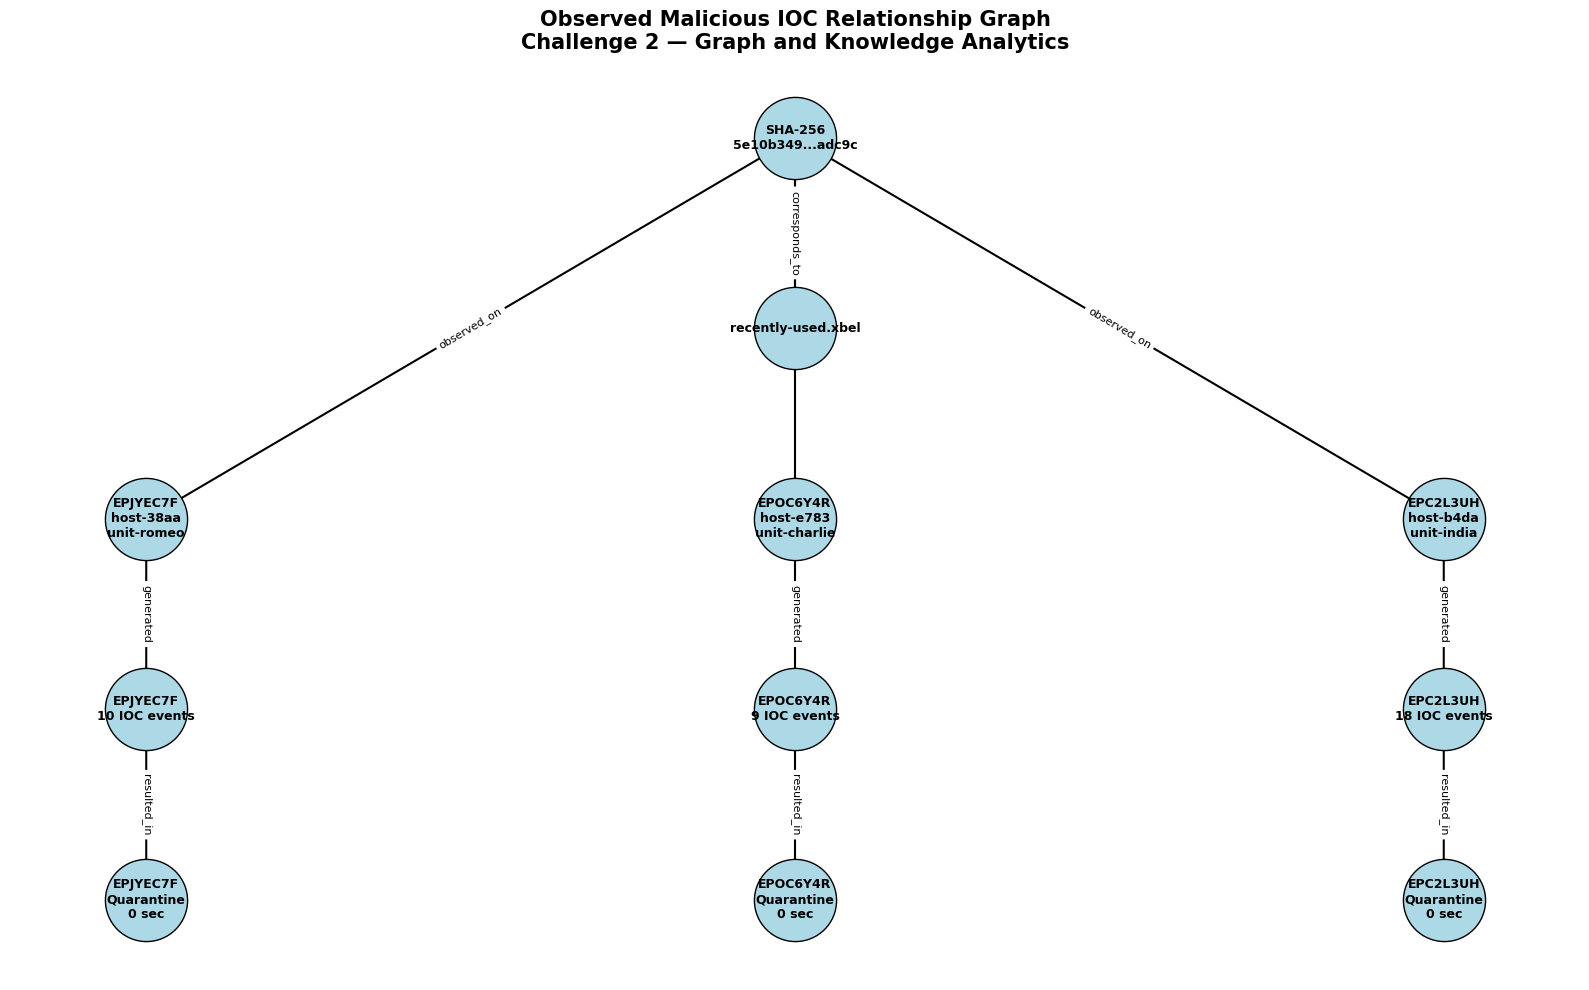

In [2]:
# Cell 98 — Render Observed IOC Relationship Graph

import matplotlib.pyplot as plt
import networkx as nx

plt.figure(figsize=(16, 10))

# Manual layout for a clean forensic relationship graph
pos = {
    "SHA-256\n5e10b349...adc9c": (0, 3),
    "recently-used.xbel": (0, 1.5),

    "EPJYEC7F\nhost-38aa\nunit-romeo": (-5, 0),
    "EPOC6Y4R\nhost-e783\nunit-charlie": (0, 0),
    "EPC2L3UH\nhost-b4da\nunit-india": (5, 0),

    "EPJYEC7F\n10 IOC events": (-5, -1.5),
    "EPOC6Y4R\n9 IOC events": (0, -1.5),
    "EPC2L3UH\n18 IOC events": (5, -1.5),

    "EPJYEC7F\nQuarantine\n0 sec": (-5, -3),
    "EPOC6Y4R\nQuarantine\n0 sec": (0, -3),
    "EPC2L3UH\nQuarantine\n0 sec": (5, -3),
}

# Draw nodes and edges
nx.draw_networkx_nodes(
    G, pos,
    node_size=3500,
    node_color="lightblue",
    edgecolors="black"
)

nx.draw_networkx_edges(
    G, pos,
    arrows=True,
    arrowsize=18,
    width=1.5
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9,
    font_weight="bold"
)

# Relationship labels
edge_labels = nx.get_edge_attributes(G, "relation")

nx.draw_networkx_edge_labels(
    G, pos,
    edge_labels=edge_labels,
    font_size=8
)

plt.title(
    "Observed Malicious IOC Relationship Graph\n"
    "Challenge 2 — Graph and Knowledge Analytics",
    fontsize=15,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()
plt.show()